<a href="https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/06.Fine_Tuning_For_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 6 -- Fine-tuning for Classification

*Companion notebook untuk* Build a Large Language Model (From Scratch) *(Sebastian Raschka, Manning 2024)*
**Technical edition -- kode buku plus beberapa pengukuran tambahan**

Di akhir Chapter 5 kita punya GPT-2 124M dengan bobot asli OpenAI, model yang pandai melanjutkan teks dan hanya itu. Beri ia awal kalimat "Every effort moves you", dan ia menulis lanjutan yang masuk akal. Tanyakan apakah sebuah SMS termasuk spam, dan ia tidak menjawab; ia malah menyalin ulang pertanyaannya. Sebentar lagi kita akan melihatnya sendiri.

Bab ini mengubah model itu menjadi *classifier*, yaitu model yang hanya memilih satu dari beberapa label tetap -- di sini "spam" atau "bukan spam". Caranya sederhana sekali. Lapisan output yang memetakan 768 angka ke 50,257 skor token diganti dengan lapisan kecil yang memetakan 768 angka ke 2 skor kelas. Sebagian besar model dibekukan, lalu sisanya dilatih dengan loss yang sama seperti saat pretraining. Di akhir bab, model yang semula hanya menyalin pertanyaan itu menebak label 95.67% pesan test dengan benar.

Yang menarik justru satu detail kecil di dalam resep ini, yang ternyata sangat menentukan perilaku model. Classifier kita membaca keputusannya dari *satu* posisi saja, yaitu posisi terakhir input. Karena pesan yang pendek diisi token pengisi (*padding*) sampai 120 token, posisi terakhir itu hampir selalu berisi token pengisi, bukan kata terakhir pesan. Detail ini akan muncul berkali-kali: ia ikut menjelaskan apa yang sebenarnya dipelajari fine-tuning, dan kenapa model yang sudah dilatih langsung gagal begitu cara padding-nya diubah. Sebelum training pun ada kejutan: head yang isinya masih acak menjawab "spam" untuk setiap pesan yang kita periksa, dengan keyakinan yang sangat tinggi, dan kita akan menelusuri dari mana keyakinan itu datang.

Notebook ini berisi semua kode bab 6 dalam urutan buku. Di beberapa titik ada pengukuran tambahan yang tidak ada di buku, diberi judul **Under the hood**; bagian-bagian itu boleh dilewati kalau hanya ingin mengikuti materi buku. Sel kode tambahan lainnya bisa dikenali dari komentar di baris pertamanya.

| Under the hood | Yang kita ukur | Hasil |
|---|---|---|
| 1. Loss awal 2.45, bukan ln 2 | Apa yang dibaca head acak sebelum training, dan kenapa loss awalnya jauh di atas tebakan 50/50 | Head acak menjawab "spam" untuk seluruh 449 pesan validation dan test, karena vektor yang dibacanya hampir sama untuk semua pesan |
| 2. Apa yang diubah fine-tuning | Bobot sebelum dan sesudah training, dan isi state optimizer | Block beku yang diperiksa (0, 5, 10) dan kedua embedding tidak bergeser sama sekali; state AdamW hanya ada untuk 7,090,946 parameter |
| 3. Token terakhir hampir selalu `<|endoftext|>` | Seberapa sering posisi yang dibaca classifier berisi padding, dan apa yang terjadi kalau cara padding diubah | 1,044 dari 1,045 pesan training berakhir dengan padding; mengubah posisi yang dibaca menjatuhkan akurasi test dari 95.67% ke 50.33% |
| 4. GPU vs CPU | Model terlatih yang sama dijalankan di dua device | Logit berbeda paling jauh 1.502e-05, dan tidak ada prediksi yang berubah |

## Setup

Output yang tersimpan di notebook ini berasal dari satu kali run di Google Colab dengan GPU (device `cuda`). Beberapa sel yang melatih ulang model -- untuk satu run kontrol, ketiga latihan, dan satu training tambahan di CPU untuk Under the hood 4 -- dimatikan di run ini, jadi bagian-bagian itu tidak punya angka hasil sendiri. Kita membahasnya saat sampai di sana.

Sel pertama memasang paket yang belum ada, lalu mencetak identitas mesin. Keberadaan paket diperiksa dengan `importlib.util.find_spec`, yang tidak ikut meng-import paketnya. `safetensors` ada di daftar karena notebook ini menyiapkan jalur kedua untuk memuat bobot GPT-2, jalur yang tidak membutuhkan TensorFlow.

In [1]:

# Dependency -- pasang paket yang belum ada sebelum import apa pun
import importlib.util
import platform
import subprocess
import sys

required = ["torch", "tiktoken", "pandas", "matplotlib", "requests", "safetensors"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("dipasang:", missing if missing else "tidak ada")

if sys.platform == "darwin":
    cpu_name = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                              capture_output=True, text=True).stdout.strip()
else:
    cpu_name = platform.processor() or platform.machine()

import torch

print(f"{cpu_name} | {platform.platform()} | Python {platform.python_version()}")
print(f"torch {torch.__version__} | cuda: {torch.cuda.is_available()} | mps: {torch.backends.mps.is_available()}")
print("tensorflow importable:", importlib.util.find_spec("tensorflow") is not None)


dipasang: tidak ada
x86_64 | Linux-6.6.122+-x86_64-with-glibc2.39 | Python 3.13.15
torch 2.11.0+cu130 | cuda: True | mps: False
tensorflow importable: True


Tidak ada yang perlu dipasang, karena runtime Colab sudah membawa semuanya. Mesinnya Linux x86_64 dengan Python 3.13.15 dan torch 2.11.0, dan CUDA tersedia, jadi training nanti berjalan di GPU NVIDIA.

Baris terakhir paling penting untuk beberapa sel berikutnya: TensorFlow bisa di-import. Buku memakai TensorFlow untuk satu hal saja, yaitu membaca checkpoint asli OpenAI di 6.4. Karena TensorFlow ada, jalur buku bisa dipakai apa adanya di run ini. Di mesin tanpa TensorFlow, notebook ini beralih ke jalur pengganti yang disiapkan di 6.4.

Repo resmi membuka bab ini dengan sel kecil yang mencetak versi paket, termasuk `tensorflow`. Sel itu menyimpan satu asumsi: semua paket di daftarnya terpasang. `importlib.metadata.version` melempar `PackageNotFoundError` untuk paket yang tidak ada, sehingga di mesin tanpa TensorFlow sel ini berhenti di tengah daftar.

Karena itu kodenya disimpan sebagai teks, lalu dijalankan di dalam `try/except`: kalau gagal, error aslinya dicetak dan notebook tetap berlanjut. Label "Kalibrasi" di baris pertama sel menandai tempat notebook ini mencocokkan isi buku dengan keadaan sebenarnya. Di sini dan di 6.4, yang dicocokkan adalah kode yang bergantung pada lingkungan tempat ia dijalankan; di 6.6, logit yang dicetak di sebuah figure.

In [2]:
# Kalibrasi #1 -- sel versi paket repo HEAD, verbatim, lewat harness
import traceback

LISTING = '''
from importlib.metadata import version

pkgs = ["matplotlib",  # Plotting library
        "numpy",       # PyTorch & TensorFlow dependency
        "tiktoken",    # Tokenizer
        "torch",       # Deep learning library
        "tensorflow",  # For OpenAI's pretrained weights
        "pandas"       # Dataset loading
       ]
for p in pkgs:
    print(f"{p} version: {version(p)}")
'''

try:
    exec(LISTING)
except Exception as e:
    traceback.print_exception(type(e), e, e.__traceback__.tb_next, limit=1, chain=False)

matplotlib version: 3.10.0
numpy version: 2.1.3
tiktoken version: 0.14.0
torch version: 2.11.0+cu130
tensorflow version: 2.21.0
pandas version: 2.2.3


Di Colab sel ini berjalan mulus dan mencetak keenam versi, termasuk TensorFlow 2.21.0. Di mesin tanpa TensorFlow, empat baris pertama akan tercetak, lalu sel berhenti di `tensorflow` dengan `PackageNotFoundError`, dan baris `pandas` tidak pernah muncul. Sel berikut mencetak daftar yang sama tanpa ikut berhenti: paket yang tidak terpasang ditandai `(not installed)`, dan `safetensors` ikut dicetak.

In [3]:

from importlib.metadata import PackageNotFoundError, version

for p in ["matplotlib", "numpy", "tiktoken", "torch", "tensorflow", "pandas", "safetensors"]:
    try:
        print(f"{p} version: {version(p)}")
    except PackageNotFoundError:
        print(f"{p} version: (not installed)")


matplotlib version: 3.10.0
numpy version: 2.1.3
tiktoken version: 0.14.0
torch version: 2.11.0+cu130
tensorflow version: 2.21.0
pandas version: 2.2.3
safetensors version: 0.8.0


Torch 2.11.0, numpy 2.1.3, dan pandas 2.2.3 di sini lebih baru daripada versi yang dicatat repo saat buku terbit (torch 2.4.0, numpy 1.26.4, pandas 2.2.2). Apakah lompatan versi ini mengubah hasil? Sepanjang bab kita akan membandingkan angka run ini dengan angka yang dicetak buku: jumlah data, loss awal, log training, sampai akurasi akhir.

## 6.1 Different categories of fine-tuning

Ada dua cara umum untuk melatih ulang (*fine-tune*) language model pretrained. *Instruction fine-tuning* melatih model dengan pasangan instruksi dan jawaban, supaya ia bisa mengerjakan perintah yang ditulis dalam bahasa sehari-hari: satu model untuk banyak tugas, tapi butuh dataset yang besar dan beragam. *Classification fine-tuning* melatih model memetakan input ke sekumpulan label yang tetap, misalnya "spam" dan "bukan spam". Model hasilnya sempit -- ia tidak bisa berbuat apa pun di luar label yang diajarkan -- tapi murah dilatih, dan hasilnya mudah dinilai, cukup dengan akurasi.

Bab ini mengerjakan yang kedua; Chapter 7 mengerjakan yang pertama.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.1.png" width="700">

**Figure 6.1** Peta tiga tahap membangun LLM. Bab ini berada di tahap 3: foundation model dari Chapter 5 diubah menjadi classifier, sedangkan cabang lainnya (Chapter 7) menjadi asisten yang mengikuti instruksi.

Perbedaan keduanya paling mudah dilihat dari input-nya. Pada instruction fine-tuning, perintahnya ikut ditulis di input, sehingga model yang sama bisa diminta memeriksa spam atau menerjemahkan.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.2.png" width="700">

**Figure 6.2** Instruction fine-tuning: perintah ("Is the following text spam? Answer with yes or no" atau "Translate into German") menjadi bagian dari input, dan satu model melayani keduanya.

Pada classification fine-tuning tidak ada perintah sama sekali. Input-nya hanya teks pesan, dan output-nya dibatasi ke dua kelas.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.3.png" width="700">

**Figure 6.3** Classification fine-tuning: input hanya berisi teks pesan, dan output-nya hanya bisa salah satu dari dua kelas.

## 6.2 Preparing the dataset

Datasetnya adalah SMS Spam Collection dari UCI: kumpulan SMS berbahasa Inggris yang masing-masing diberi label `ham` (pesan biasa) atau `spam`. Pekerjaan pertama kita adalah mengubah file mentah itu menjadi tiga set yang siap dipakai: unduh, seimbangkan jumlah kedua kelas, bagi menjadi train, validation, dan test, lalu simpan sebagai CSV.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.4.png" width="700">

**Figure 6.4** Tiga tahap classification fine-tuning: menyiapkan dataset (langkah 1-3), menyiapkan model (langkah 4-7), lalu fine-tuning, evaluasi, dan pemakaian (langkah 8-10). Kita mulai dari langkah 1.

Listing 6.1 di sel berikut adalah versi repo terbaru. Bedanya dengan versi yang dipakai buku: unduhan kini memakai library `requests` dengan batas waktu 60 detik dan ditulis ke disk sepotong demi sepotong, bukan `urllib.request`. Kalau URL UCI gagal, kedua versi sama-sama beralih ke URL cadangan. Versi `urllib` itu tetap disimpan di akhir sel sebagai string.

In [4]:
import requests
import zipfile
import os
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extracted_path = "sms_spam_collection"
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"


def download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path):
    if data_file_path.exists():
        print(f"{data_file_path} already exists. Skipping download and extraction.")
        return

    # Downloading the file
    response = requests.get(url, stream=True, timeout=60)
    response.raise_for_status()
    with open(zip_path, "wb") as out_file:
        for chunk in response.iter_content(chunk_size=8192):
            if chunk:
                out_file.write(chunk)

    # Unzipping the file
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extracted_path)

    # Add .tsv file extension
    original_file_path = Path(extracted_path) / "SMSSpamCollection"
    os.rename(original_file_path, data_file_path)
    print(f"File downloaded and saved as {data_file_path}")


try:
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)
except (requests.exceptions.RequestException, TimeoutError) as e:
    print(f"Primary URL failed: {e}. Trying backup URL...")
    url = "https://f001.backblazeb2.com/file/LLMs-from-scratch/sms%2Bspam%2Bcollection.zip"
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)



# The book originally used the following code below
# However, urllib uses older protocol settings that
# can cause problems for some readers using a VPN.
# The `requests` version above is more robust
# in that regard.

"""
import urllib.request
import zipfile
import os
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extracted_path = "sms_spam_collection"
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"

def download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path):
    if data_file_path.exists():
        print(f"{data_file_path} already exists. Skipping download and extraction.")
        return

    # Downloading the file
    with urllib.request.urlopen(url) as response:
        with open(zip_path, "wb") as out_file:
            out_file.write(response.read())

    # Unzipping the file
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extracted_path)

    # Add .tsv file extension
    original_file_path = Path(extracted_path) / "SMSSpamCollection"
    os.rename(original_file_path, data_file_path)
    print(f"File downloaded and saved as {data_file_path}")

try:
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)
except (urllib.error.HTTPError, urllib.error.URLError, TimeoutError) as e:
    print(f"Primary URL failed: {e}. Trying backup URL...")
    url = "https://f001.backblazeb2.com/file/LLMs-from-scratch/sms%2Bspam%2Bcollection.zip"
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)
"""

File downloaded and saved as sms_spam_collection/SMSSpamCollection.tsv


'\nimport urllib.request\nimport zipfile\nimport os\nfrom pathlib import Path\n\nurl = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"\nzip_path = "sms_spam_collection.zip"\nextracted_path = "sms_spam_collection"\ndata_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"\n\ndef download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path):\n    if data_file_path.exists():\n        print(f"{data_file_path} already exists. Skipping download and extraction.")\n        return\n\n    # Downloading the file\n    with urllib.request.urlopen(url) as response:\n        with open(zip_path, "wb") as out_file:\n            out_file.write(response.read())\n\n    # Unzipping the file\n    with zipfile.ZipFile(zip_path, "r") as zip_ref:\n        zip_ref.extractall(extracted_path)\n\n    # Add .tsv file extension\n    original_file_path = Path(extracted_path) / "SMSSpamCollection"\n    os.rename(original_file_path, data_file_path)\n    print(f"File downloade

File berhasil diunduh dari URL UCI yang utama -- tidak ada pesan "Trying backup URL" -- lalu diekstrak dan diberi ekstensi `.tsv` oleh `os.rename`.

Blok panjang di bawahnya bukan hasil kode yang berjalan. String bertanda kutip tiga di akhir sel adalah ekspresi terakhir sel itu, dan Jupyter selalu menampilkan nilai ekspresi terakhir, jadi isi string -- versi `urllib` dari buku -- ikut tercetak. Komentar di kode menjelaskan kenapa versi itu diganti: `urllib` memakai pengaturan protokol lama yang bermasalah bagi sebagian pembaca yang memakai VPN.

In [5]:
import pandas as pd

df = pd.read_csv(data_file_path, sep="\t", header=None, names=["Label", "Text"])
df

,Label,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


Dataset-nya berisi 5,572 pesan dalam dua kolom, sama dengan tabel di Figure 6.5 buku; figure itu tidak ditampilkan terpisah karena tabel di atas sudah menggantikannya. File `.tsv` itu tidak punya baris judul kolom, jadi nama `Label` dan `Text` diberikan lewat `names=`.

Perhatikan juga isinya: bahasa SMS apa adanya, seperti "U dun say so early hor...", tanpa dirapikan sama sekali. Itu tidak masalah, karena tokenizer BPE GPT-2 bisa memecah teks apa pun menjadi token. Pertanyaan pertama yang perlu dijawab justru lain: berapa banyak spam di antara 5,572 pesan ini?

In [6]:
print(df["Label"].value_counts())

Label
ham     4825
spam     747
Name: count, dtype: int64


Hanya 747 pesan yang spam, sekitar 13.4% dari seluruh data. Ketimpangan seperti ini menjebak. Classifier yang selalu menjawab "ham" tanpa membaca apa pun sudah mendapat akurasi 86.6% -- angka yang terlihat bagus, padahal modelnya tidak berguna sama sekali.

Karena itu buku menyeimbangkan kedua kelas lebih dulu. Dengan porsi 50/50, model yang menebak asal hanya mendapat sekitar 50%, sehingga setiap kenaikan di atas itu memang hasil belajar.

In [7]:
def create_balanced_dataset(df):

    # Count the instances of "spam"
    num_spam = df[df["Label"] == "spam"].shape[0]

    # Randomly sample "ham" instances to match the number of "spam" instances
    ham_subset = df[df["Label"] == "ham"].sample(num_spam, random_state=123)

    # Combine ham "subset" with "spam"
    balanced_df = pd.concat([ham_subset, df[df["Label"] == "spam"]])

    return balanced_df


balanced_df = create_balanced_dataset(df)
print(balanced_df["Label"].value_counts())

Label
ham     747
spam    747
Name: count, dtype: int64


Listing 6.2 menyeimbangkan kelas dengan *undersampling*: semua 747 spam dipertahankan, 747 pesan ham diambil secara acak dengan `random_state=123`, dan 4,078 pesan ham sisanya dibuang. Dataset menyusut dari 5,572 menjadi 1,494 pesan. Ukuran sekecil ini disengaja, supaya fine-tuning selesai dalam hitungan menit, bahkan di laptop.

Pesan ham mana yang terpilih ditentukan oleh seed, bukan oleh mesin: `df.sample` memakai generator acak NumPy (`RandomState`) dengan seed 123. Kalau pandas 2.2.3 di sini memilih subset yang sama dengan run di buku, angka-angka berikutnya juga akan sama dengan yang dicetak buku. Kita akan melihat bahwa memang begitu.

In [8]:
balanced_df["Label"] = balanced_df["Label"].map({"ham": 0, "spam": 1})

In [9]:
balanced_df

,Label,Text
4307,0,Awww dat is sweet! We can think of something t...
4138,0,Just got to &lt;#&gt;
4831,0,"The word ""Checkmate"" in chess comes from the P..."
4461,0,This is wishing you a great day. Moji told me ...
5440,0,Thank you. do you generally date the brothas?
...,...,...
5537,1,Want explicit SEX in 30 secs? Ring 02073162414...
5540,1,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...
5547,1,Had your contract mobile 11 Mnths? Latest Moto...
5566,1,REMINDER FROM O2: To get 2.50 pounds free call...


Label teks kini menjadi angka: `ham` menjadi 0, dan `spam` menjadi 1. Dua angka ini nantinya berperan seperti token ID, hanya saja untuk 2 kelas, bukan 50,257 token.

Kolom indeks di kiri masih membawa nomor baris asli dari dataset. Ke-747 pesan ham hasil sampling muncul lebih dulu dengan nomor yang acak (4307, 4138, ...), disusul 747 pesan spam dalam urutan aslinya (sampai 5567). Data yang berkelompok seperti ini harus diacak sebelum dibagi, dan itulah yang dikerjakan listing berikutnya.

In [10]:
def random_split(df, train_frac, validation_frac):
    # Shuffle the entire DataFrame
    df = df.sample(frac=1, random_state=123).reset_index(drop=True)

    # Calculate split indices
    train_end = int(len(df) * train_frac)
    validation_end = train_end + int(len(df) * validation_frac)

    # Split the DataFrame
    train_df = df[:train_end]
    validation_df = df[train_end:validation_end]
    test_df = df[validation_end:]

    return train_df, validation_df, test_df

train_df, validation_df, test_df = random_split(balanced_df, 0.7, 0.1)
# Test size is implied to be 0.2 as the remainder

train_df.to_csv("train.csv", index=None)
validation_df.to_csv("validation.csv", index=None)
test_df.to_csv("test.csv", index=None)

Listing 6.3 mengacak seluruh 1,494 baris dengan `frac=1` dan `random_state=123`, lalu memotongnya menjadi 70% train, 10% validation, dan sisanya test. Buku tidak mencetak hasil potongan ini, jadi sel berikut memeriksanya.

In [11]:

for name, part in [("train", train_df), ("validation", validation_df), ("test", test_df)]:
    print(f"{name:>10}: {len(part):4d} rows | spam fraction {part['Label'].mean():.3f}")
print(f"{'total':>10}: {len(train_df) + len(validation_df) + len(test_df):4d}")


     train: 1045 rows | spam fraction 0.495
validation:  149 rows | spam fraction 0.530
      test:  300 rows | spam fraction 0.503
     total: 1494


Train mendapat 1,045 baris, karena `int(1494 * 0.7)` membulatkan 1045.8 ke bawah. Validation mendapat `int(1494 * 0.1)`, yaitu 149 baris, dan test mendapat sisanya, 300 baris, sedikit lebih dari 20%.

Pembagian ini acak biasa, bukan *stratified* (yang menjaga porsi setiap kelas tetap sama di semua bagian), jadi porsi spam-nya tidak persis 0.5: 0.495 di train, 0.530 di validation, dan 0.503 di test. Porsi seperti ini akan muncul lagi beberapa kali, karena model yang menjawab "spam" untuk semua pesan mendapat akurasi persis sebesar porsi spam di data yang dinilai. Di Under the hood 3, misalnya, angka 50.33% adalah 151 pesan spam dari 300 pesan test.

Sebelum kita mempercayai akurasi test nanti, sel berikut memeriksa satu hal lagi: pesan yang muncul di train sekaligus di validation atau test.

In [12]:

# Overlap teks antar-split: baris held-out yang teksnya persis sama dengan baris train
train_texts = set(train_df["Text"])
for name, part in [("validation", validation_df), ("test", test_df)]:
    dup = part["Text"].isin(train_texts)
    print(f"{name:>10}: {dup.sum():3d}/{len(part)} baris berteks persis sama dengan baris train "
          f"(porsi spam di baris itu {part.loc[dup, 'Label'].mean():.2f})")
print(f"     train: {train_df['Text'].duplicated().sum()} baris berteks duplikat di dalam train sendiri")
print(f"   dataset: {df['Text'].duplicated().sum()} dari {len(df)} baris berteks duplikat (sebelum balancing)")


validation:  13/149 baris berteks persis sama dengan baris train (porsi spam di baris itu 0.77)
      test:  37/300 baris berteks persis sama dengan baris train (porsi spam di baris itu 0.89)
     train: 48 baris berteks duplikat di dalam train sendiri
   dataset: 403 dari 5572 baris berteks duplikat (sebelum balancing)


Pesan seperti itu ada, dan jumlahnya tidak sedikit. Dari 5,572 pesan di dataset asli, 403 adalah salinan ulang dari teks yang sudah muncul lebih dulu; `duplicated()` tidak menghitung kemunculan pertamanya, jadi pesan yang punya kembaran persis jumlahnya lebih dari 403. Listing 6.3 membagi data per *baris*, bukan per teks unik, sehingga 37 dari 300 baris test dan 13 dari 149 baris validation punya kembaran persis di train. Kembaran di test kebanyakan spam (porsi spam-nya 0.89), cocok dengan sifat spam yang dikirim massal dengan teks yang sama.

Notebook ini tidak membuang duplikat dan tidak mengubah pembagian buku, karena semua angka buku bergantung pada pembagian ini. Tapi akibatnya perlu diingat: akurasi validation dan test di bab ini adalah akurasi pada baris yang tidak dipakai untuk training, bukan pada teks yang dijamin belum pernah dilihat model. Di 6.7 kita akan memisahkan akurasi test untuk kedua kelompok baris itu.

## 6.3 Creating data loaders

Di Chapter 2, teks panjang dipotong dengan sliding window menjadi potongan yang sama panjang. Cara itu tidak cocok di sini. Setiap SMS adalah satu contoh dengan satu label, dan panjangnya berbeda-beda, padahal untuk ditumpuk menjadi satu tensor batch, semua contoh harus sama panjang.

Ada dua jalan keluar. Kita bisa memotong semua pesan sepanjang pesan terpendek, yang murah tapi membuang isi pesan. Atau kita bisa mengisi semua pesan dengan token pengisi sampai sepanjang pesan terpanjang, sehingga isinya utuh, dengan sedikit komputasi tambahan. Buku memilih cara kedua, *padding*, dengan token `<|endoftext|>` sebagai pengisi.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.6.png" width="700">

**Figure 6.6** Persiapan input: setiap pesan diubah menjadi token ID, lalu pesan yang lebih pendek diisi token ID 50256 sampai sepanjang pesan terpanjang.

In [13]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

[50256]


`<|endoftext|>` adalah token ID 50256, ID tertinggi di kosakata GPT-2 yang berisi 50,257 token (ID 0 sampai 50256). Argumen `allowed_special` wajib diberikan: secara bawaan tiktoken menolak meng-encode teks yang mengandung token khusus, supaya string `<|endoftext|>` yang kebetulan ada di teks pengguna tidak diam-diam berubah menjadi token kontrol.

Angka 50256 ini perlu diingat. Token inilah yang nanti mengisi posisi paling menentukan di input classifier kita.

In [14]:
import torch
from torch.utils.data import Dataset


class SpamDataset(Dataset):
    def __init__(self, csv_file, tokenizer, max_length=None, pad_token_id=50256):
        self.data = pd.read_csv(csv_file)

        # Pre-tokenize texts
        self.encoded_texts = [
            tokenizer.encode(text) for text in self.data["Text"]
        ]

        if max_length is None:
            self.max_length = self._longest_encoded_length()
        else:
            self.max_length = max_length
            # Truncate sequences if they are longer than max_length
            self.encoded_texts = [
                encoded_text[:self.max_length]
                for encoded_text in self.encoded_texts
            ]

        # Pad sequences to the longest sequence
        self.encoded_texts = [
            encoded_text + [pad_token_id] * (self.max_length - len(encoded_text))
            for encoded_text in self.encoded_texts
        ]

    def __getitem__(self, index):
        encoded = self.encoded_texts[index]
        label = self.data.iloc[index]["Label"]
        return (
            torch.tensor(encoded, dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )

    def __len__(self):
        return len(self.data)

    def _longest_encoded_length(self):
        max_length = 0
        for encoded_text in self.encoded_texts:
            encoded_length = len(encoded_text)
            if encoded_length > max_length:
                max_length = encoded_length
        return max_length
        # Note: A more pythonic version to implement this method
        # is the following, which is also used in the next chapter:
        # return max(len(encoded_text) for encoded_text in self.encoded_texts)

Listing 6.4 mengerjakan semuanya di `__init__`. Pertama, semua pesan diubah menjadi token ID sekaligus. Kedua, `max_length` ditentukan: kalau `None`, dipakai panjang pesan terpanjang di file itu; kalau diberi angka, pesan yang lebih panjang dipotong. Ketiga, setiap pesan ditambahi `pad_token_id` di sebelah kanan sampai sepanjang `max_length`.

Arah padding ini kelihatannya detail kecil. Tapi classifier yang nanti kita bangun membaca keputusannya dari posisi terakhir, dan dengan padding di kanan, posisi terakhir itu biasanya berisi token pengisi. Under the hood 3 akan mengukur seberapa besar akibatnya.

In [15]:
train_dataset = SpamDataset(
    csv_file="train.csv",
    max_length=None,
    tokenizer=tokenizer
)

print(train_dataset.max_length)

120


Pesan training terpanjang berisi 120 token, jauh di bawah batas 1,024 posisi yang bisa dibaca GPT-2. Angka ini hanya ditentukan dari train set. Validation dan test di sel berikut dipaksa ke panjang yang sama -- dan dipotong kalau ada pesan yang lebih panjang -- sehingga ketiga set berbentuk `[n, 120]`, dan model melihat susunan input yang sama saat training maupun evaluasi.

In [16]:
val_dataset = SpamDataset(
    csv_file="validation.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)
test_dataset = SpamDataset(
    csv_file="test.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)

Apakah ada pesan validation atau test yang terpotong? Kita periksa sebentar lagi, bersama sebaran panjang pesan di ketiga set.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.7.png" width="700">

**Figure 6.7** Satu batch training: 8 pesan, masing-masing 120 token ID (diakhiri padding 50256), ditambah vektor berisi 8 label kelas 0 atau 1.

> **Exercise 6.1 -- Increasing the context length.** Isi input dengan padding sampai panjang maksimum yang bisa dibaca model (1,024 token), lalu amati pengaruhnya pada performa prediksi. Dibahas di bagian Exercises di akhir notebook.

In [17]:

# Sensus panjang token per split (sebelum padding) -- angka yang tidak dicetak buku
import statistics

N_LONG = {}
for name, frame in [("train", train_df), ("validation", validation_df), ("test", test_df)]:
    lengths = [len(tokenizer.encode(t)) for t in frame["Text"]]
    N_LONG[name] = sum(n > train_dataset.max_length for n in lengths)
    print(f"{name:>10}: min {min(lengths):3d} | median {statistics.median(lengths):5.1f} | "
          f"max {max(lengths):3d} | > {train_dataset.max_length}: {N_LONG[name]}")


     train: min   2 | median  32.0 | max 120 | > 120: 0
validation: min   5 | median  36.0 | max  71 | > 120: 0
      test: min   2 | median  32.0 | max  92 | > 120: 0


Pesan tipikal jauh lebih pendek dari 120 token: median panjang pesan training hanya 32 token. Jadi untuk pesan tipikal, 88 dari 120 posisi di input adalah token pengisi, sekitar 73%. Pesan terpanjang di validation (71 token) dan test (92 token) juga di bawah 120, sehingga pemotongan di listing 6.4 tidak membuang apa pun di dataset ini; ia hanya jaring pengaman.

Angka 73% ini layak diingat. Sebagian besar posisi yang dilihat model adalah token pengisi yang sama, dan posisi paling akhir -- yang nanti dibaca classifier -- hampir selalu termasuk di antaranya.

In [18]:
from torch.utils.data import DataLoader

num_workers = 0
batch_size = 8

torch.manual_seed(123)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    drop_last=True,
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)

Listing 6.5 membungkus ketiga dataset menjadi `DataLoader` dengan batch berisi 8 pesan. Hanya `train_loader` yang mengacak urutan (`shuffle=True`) dan membuang batch terakhir yang tidak penuh (`drop_last=True`). Validation dan test dibaca berurutan, dan batch terakhirnya boleh berisi kurang dari 8 pesan.

`torch.manual_seed(123)` di sel itu sebenarnya belum terpakai saat loader dibuat. Urutan acak baru diambil dari generator acak global setiap kali sebuah loop `for ... in train_loader` dimulai, dan loop atas `DataLoader` mana pun, termasuk yang tidak diacak, juga mengambil satu angka dari generator yang sama. Akibatnya, setiap sel yang mengiterasi loader ikut menentukan urutan batch training yang dilihat sel-sel sesudahnya, kecuali kalau seed disetel ulang -- seperti yang dilakukan beberapa listing berikutnya tepat sebelum memakai `train_loader`.

In [19]:
print("Train loader:")
for input_batch, target_batch in train_loader:
    pass

print("Input batch dimensions:", input_batch.shape)
print("Label batch dimensions", target_batch.shape)

Train loader:
Input batch dimensions: torch.Size([8, 120])
Label batch dimensions torch.Size([8])


Satu batch input berbentuk `[8, 120]`: delapan pesan, masing-masing 120 token. Label-nya berbentuk `[8]`, satu angka 0 atau 1 per pesan. Loop di atas berjalan sampai batch terakhir, dan batch itu tetap berisi 8 pesan, karena `drop_last=True` sudah membuang sisanya.

In [20]:
print(f"{len(train_loader)} training batches")
print(f"{len(val_loader)} validation batches")
print(f"{len(test_loader)} test batches")

130 training batches
19 validation batches
38 test batches


Hasilnya 130 batch training, 19 batch validation, dan 38 batch test. Hitungannya mudah. 1,045 pesan training dibagi 8 menghasilkan 130 batch penuh, dan 5 pesan sisanya dibuang di setiap epoch; pesan mana yang terbuang bergantung pada urutan acak epoch itu. Validation memakai 19 batch, yang terakhir berisi 5 pesan, dan test 38 batch, yang terakhir berisi 4 pesan.

Dari sini kita juga tahu skala training nanti: satu epoch berarti 130 langkah optimizer atau 1,040 contoh, dan lima epoch berarti 650 langkah dan 5,200 contoh.

## 6.4 Initializing a model with pretrained weights

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.8.png" width="700">

**Figure 6.8** Tahap 1 (dataset) selesai. Tahap 2 dimulai dengan membuat model dan memuat bobot pretrained.

Model yang akan di-fine-tune adalah GPT-2 124M dengan bobot asli OpenAI, bukan model kecil yang kita latih sendiri di Chapter 5. Seperti saat memuat bobot OpenAI di Chapter 5, konfigurasinya memakai `qkv_bias=True`, karena GPT-2 asli memakai bias di proyeksi query, key, dan value. Bedanya ada di dropout. Chapter 5 mewarisi `drop_rate` 0.1 dari konfigurasi awalnya dan hanya mematikannya lewat `eval()`, sedangkan di sini `drop_rate=0.0` sejak awal, termasuk selama training.

Dropout nol membuat setiap forward pass deterministik, juga saat training: input yang sama selalu memberi output yang sama. Itulah yang memungkinkan angka-angka di bawah dibandingkan langsung dengan buku. Konsekuensinya, fine-tuning di bab ini berjalan tanpa regularisasi dropout. Versi repo juga menambahkan satu `assert`, yang memastikan panjang input dataset (120) tidak melebihi panjang konteks model (1,024).

In [21]:
CHOOSE_MODEL = "gpt2-small (124M)"
INPUT_PROMPT = "Every effort moves"

BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

assert train_dataset.max_length <= BASE_CONFIG["context_length"], (
    f"Dataset length {train_dataset.max_length} exceeds model's context "
    f"length {BASE_CONFIG['context_length']}. Reinitialize data sets with "
    f"`max_length={BASE_CONFIG['context_length']}`"
)

Listing 6.6 butuh dua hal dari luar notebook: kelas `GPTModel` beserta fungsi pemuat bobotnya, yang ditulis di bab-bab sebelumnya, dan fungsi untuk mengunduh bobot OpenAI. Untuk yang pertama, versi cetaknya meng-import dari modul `chapter04` dan `chapter05`, modul yang tidak ada di repo mana pun, karena buku mengandaikan pembaca menyimpan sendiri kode bab-bab sebelumnya. Repo resmi mengumpulkan kode itu di file `previous_chapters.py`. Fungsi unduhannya, di kedua versi, berasal dari `gpt_download.py`, yang membaca checkpoint TensorFlow OpenAI.

Notebook ini menyediakan modul-modul yang diandaikan listing itu, tanpa mengubah listing-nya. Pekerjaannya dibagi ke tiga sel, dan dua sel terakhir diberi label Kalibrasi #2:

1. Sel pertama berisi kode `previous_chapters.py` dari repo, apa adanya: dataset sliding window (Chapter 2), multi-head attention (Chapter 3), `GPTModel` dan greedy decoding (Chapter 4), serta pemuat bobot (Chapter 5).
2. Sel kedua mendaftarkan definisi-definisi itu sebagai modul `previous_chapters`, sekaligus sebagai `chapter04` dan `chapter05`, sehingga baris import versi repo maupun versi cetak sama-sama berjalan.
3. Sel ketiga menyiapkan `gpt_download`: file resmi dari repo kalau TensorFlow tersedia, atau pengganti yang tidak membutuhkan TensorFlow kalau tidak.

In [22]:
# Copyright (c) Sebastian Raschka under Apache License 2.0 (see LICENSE.txt).
# Source for "Build a Large Language Model From Scratch"
#   - https://www.manning.com/books/build-a-large-language-model-from-scratch
# Code: https://github.com/rasbt/LLMs-from-scratch
#
# This file collects all the relevant code that we covered thus far
# throughout Chapters 2-5.
# This file can be run as a standalone script.

import numpy as np
import tiktoken
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

#####################################
# Chapter 2
#####################################


class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True, num_workers=0):
    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last, num_workers=num_workers)

    return dataloader


#####################################
# Chapter 3
#####################################
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by n_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads  # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.reshape(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)  # optional projection

        return context_vec


#####################################
# Chapter 4
#####################################
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift


class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_resid = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)   # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_resid(x)
        x = x + shortcut  # Add the original input back

        # Shortcut connection for feed-forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_resid(x)
        x = x + shortcut  # Add the original input back

        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits


def generate_text_simple(model, idx, max_new_tokens, context_size):
    # idx is (B, T) array of indices in the current context
    for _ in range(max_new_tokens):

        # Crop current context if it exceeds the supported context size
        # E.g., if LLM supports only 5 tokens, and the context size is 10
        # then only the last 5 tokens are used as context
        idx_cond = idx[:, -context_size:]

        # Get the predictions
        with torch.no_grad():
            logits = model(idx_cond)

        # Focus only on the last time step
        # (batch, n_token, vocab_size) becomes (batch, vocab_size)
        logits = logits[:, -1, :]

        # Get the idx of the vocab entry with the highest logits value
        idx_next = torch.argmax(logits, dim=-1, keepdim=True)  # (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch, n_tokens+1)

    return idx


#####################################
# Chapter 5
#####################################
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))


def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe"])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params["wte"])

    for b in range(len(params["blocks"])):
        q_w, k_w, v_w = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params["blocks"][b]["attn"]["c_proj"]["b"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])


def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)  # add batch dimension
    return encoded_tensor


def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)  # remove batch dimension
    return tokenizer.decode(flat.tolist())

In [23]:

# Pelengkapan Kalibrasi #2 -- modul yang diimpor listing 6.6 (repo) dan versi cetaknya (buku)
import sys
import types

previous_chapters = types.ModuleType("previous_chapters")
for name in ["GPTDatasetV1", "create_dataloader_v1", "MultiHeadAttention", "LayerNorm", "GELU",
             "FeedForward", "TransformerBlock", "GPTModel", "generate_text_simple", "assign",
             "load_weights_into_gpt", "text_to_token_ids", "token_ids_to_text"]:
    setattr(previous_chapters, name, globals()[name])
for module_name in ("previous_chapters", "chapter04", "chapter05"):
    sys.modules[module_name] = previous_chapters
print("modul terdaftar:", [m for m in ("previous_chapters", "chapter04", "chapter05") if m in sys.modules])


modul terdaftar: ['previous_chapters', 'chapter04', 'chapter05']


Ketiga nama modul menunjuk ke objek modul yang sama. Python selalu memeriksa `sys.modules` sebelum mencari file, jadi `from previous_chapters import GPTModel` di listing 6.6 akan mengambil kelas yang baru saja didefinisikan di atas, tanpa perlu file di disk.

In [24]:
# Kalibrasi #2 -- sumber bobot pretrained tanpa TensorFlow.
# gpt_download.py resmi membaca checkpoint TF OpenAI dan butuh `import tensorflow`. Bila TensorFlow
# tidak bisa di-import, sel ini mendaftarkan modul `gpt_download` pengganti dengan fungsi
# download_and_load_gpt2 bersignature dan bernilai balik sama (settings, params), bersumber dari
# model.safetensors resmi huggingface.co/openai-community -- jalur alternatif yang juga dipakai repo
# (ch05/02_alternative_weight_loading/weight-loading-hf-safetensors.ipynb). Cache HF lokal dibaca
# read-only; tanpa cache, file diunduh dari URL resmi. Listing 6.6 lalu berjalan verbatim.
import hashlib
import importlib.util
import os
import sys
import types

import requests

TF_AVAILABLE = importlib.util.find_spec("tensorflow") is not None

# model_size -> (repo openai-community, n_head, ukuran byte, sha256 = LFS oid resmi; dicek 2026-10-14)
HF_GPT2 = {
    "124M": ("gpt2", 12, 548105171, "248dfc3911869ec493c76e65bf2fcf7f615828b0254c12b473182f0f81d3a707"),
    "355M": ("gpt2-medium", 16, 1519984962, "fc5a354a19255ad494f3d71549390baca1ccf61d1d822b9408971705c687c9cd"),
    "774M": ("gpt2-large", 20, 3247159078, "5f47f3e12f91cd33b662ce7e433b6150ad5512b5884a2cee961b50e9c3bbebce"),
    "1558M": ("gpt2-xl", 25, 6431829964, "0f8b28eb05a8075f48b61b6f35332978c74fc7763fa9fb4051a1c30511736a6a"),
}


def _hf_cached_file(repo, filename):
    """Path file di cache HF standar (read-only, tanpa jaringan) atau (None, None)."""
    hub = os.environ.get("HF_HUB_CACHE") or os.path.join(
        os.environ.get("HF_HOME", os.path.join(os.path.expanduser("~"), ".cache", "huggingface")), "hub")
    repo_dir = os.path.join(hub, "models--" + repo.replace("/", "--"))
    ref = os.path.join(repo_dir, "refs", "main")
    if not os.path.exists(ref):
        return None, None
    with open(ref, encoding="utf-8") as f:
        rev = f.read().strip()
    path = os.path.join(repo_dir, "snapshots", rev, filename)
    return (path, rev) if os.path.exists(path) else (None, None)


def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            h.update(chunk)
    return h.hexdigest()


def _hf_to_openai_params(sd, n_layer):
    """Key HF GPT-2 -> struktur `params` checkpoint TF OpenAI. Hanya ganti nama, tanpa transpose:
    Conv1D HF menyimpan bobot (in, out), layout yang sama dengan checkpoint TF."""
    params = {"wte": sd["wte.weight"], "wpe": sd["wpe.weight"],
              "g": sd["ln_f.weight"], "b": sd["ln_f.bias"], "blocks": []}
    for b in range(n_layer):
        h = f"h.{b}."
        params["blocks"].append({
            "attn": {"c_attn": {"w": sd[h + "attn.c_attn.weight"], "b": sd[h + "attn.c_attn.bias"]},
                     "c_proj": {"w": sd[h + "attn.c_proj.weight"], "b": sd[h + "attn.c_proj.bias"]}},
            "mlp": {"c_fc": {"w": sd[h + "mlp.c_fc.weight"], "b": sd[h + "mlp.c_fc.bias"]},
                    "c_proj": {"w": sd[h + "mlp.c_proj.weight"], "b": sd[h + "mlp.c_proj.bias"]}},
            "ln_1": {"g": sd[h + "ln_1.weight"], "b": sd[h + "ln_1.bias"]},
            "ln_2": {"g": sd[h + "ln_2.weight"], "b": sd[h + "ln_2.bias"]},
        })
    return params


def download_and_load_gpt2(model_size, models_dir):
    """Pengganti TF-free untuk gpt_download.download_and_load_gpt2."""
    from safetensors.numpy import load_file
    if model_size not in HF_GPT2:
        raise ValueError(f"Model size not in {tuple(HF_GPT2)}")
    repo_name, n_head, n_bytes, oid = HF_GPT2[model_size]
    repo = f"openai-community/{repo_name}"
    path, rev = _hf_cached_file(repo, "model.safetensors")
    if path is not None:
        print(f"source: HF cache {repo}@{rev[:12]} (read-only)")
    else:
        path = os.path.join(models_dir, model_size, "model.safetensors")
        url = f"https://huggingface.co/{repo}/resolve/main/model.safetensors"
        if not os.path.exists(path):
            os.makedirs(os.path.dirname(path), exist_ok=True)
            response = requests.get(url, stream=True, timeout=60)
            response.raise_for_status()
            with open(path + ".part", "wb") as f:
                for chunk in response.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
            os.rename(path + ".part", path)
        print(f"source: {url}")
    digest = _sha256(path)
    print(f"model.safetensors: {os.path.getsize(path):,} bytes, sha256 {digest[:16]}..., "
          f"official LFS oid match: {digest == oid}")
    if digest != oid:
        raise ValueError(f"sha256 {digest} != official oid {oid}")
    sd = load_file(path)
    n_layer = 1 + max(int(k.split(".")[1]) for k in sd if k.startswith("h."))
    settings = {"n_vocab": sd["wte.weight"].shape[0], "n_ctx": sd["wpe.weight"].shape[0],
                "n_embd": sd["wte.weight"].shape[1], "n_head": n_head, "n_layer": n_layer}
    return settings, _hf_to_openai_params(sd, n_layer)


if TF_AVAILABLE:
    UPSTREAM_COMMIT = "cdbd33e6d57a71e20ea31434841095fac50cecd8"
    if not os.path.exists("gpt_download.py"):
        r = requests.get("https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/"
                         f"{UPSTREAM_COMMIT}/ch06/01_main-chapter-code/gpt_download.py", timeout=60)
        r.raise_for_status()
        with open("gpt_download.py", "wb") as f:
            f.write(r.content)
    print("tensorflow importable -> listing 6.6 memakai gpt_download.py resmi (checkpoint TF OpenAI)")
else:
    _shim = types.ModuleType("gpt_download")
    _shim.download_and_load_gpt2 = download_and_load_gpt2
    _shim.__file__ = "<TF-free shim: huggingface.co/openai-community model.safetensors>"
    sys.modules["gpt_download"] = _shim
    print("tensorflow not importable -> modul gpt_download = shim TF-free (HF safetensors resmi)")

tensorflow importable -> listing 6.6 memakai gpt_download.py resmi (checkpoint TF OpenAI)


Karena TensorFlow tersedia, sel ini mengambil `gpt_download.py` resmi dari satu commit tertentu di repo, dan listing 6.6 akan mengunduh checkpoint TensorFlow OpenAI persis seperti di buku. Jalur pengganti yang didefinisikan di sel yang sama tidak terpakai di run ini, tapi beberapa fungsinya dipakai lagi dua sel kemudian, jadi ada gunanya memahami cara kerjanya.

Jalur pengganti itu membaca file `model.safetensors` GPT-2 dari Hugging Face. *Safetensors* adalah format penyimpanan tensor yang tidak membutuhkan TensorFlow, dan file ini berisi bobot OpenAI yang sama, dikonversi oleh Hugging Face; notebook alternatif di repo resmi (`ch05/02_alternative_weight_loading`) juga memakainya. Fungsi `download_and_load_gpt2` pengganti mengembalikan `settings` dan `params` dengan bentuk yang sama seperti fungsi aslinya, sehingga listing 6.6 tidak perlu diubah sedikit pun. Pemetaannya cukup mengganti nama -- `wte.weight` menjadi `wte`, `h.0.attn.c_attn.weight` menjadi `blocks[0].attn.c_attn.w`, dan seterusnya -- tanpa transpose, karena Hugging Face menyimpan bobot lapisan-lapisan ini dalam susunan `(in, out)` yang sama dengan checkpoint TensorFlow. Sebelum dipakai, sidik jari file itu dicocokkan dengan nilai resmi dari Hugging Face.

Ada satu jenis key di file Hugging Face yang sengaja tidak dipetakan, yaitu `h.{b}.attn.bias`. Namanya menyesatkan: isinya bukan bias yang dilatih, melainkan causal mask milik implementasi Hugging Face, sedangkan `GPTModel` membuat mask-nya sendiri.

In [25]:
from gpt_download import download_and_load_gpt2
from previous_chapters import GPTModel, load_weights_into_gpt
# If the `previous_chapters.py` file is not available locally,
# you can import it from the `llms-from-scratch` PyPI package.
# For details, see: https://github.com/rasbt/LLMs-from-scratch/tree/main/pkg
# E.g.,
# from llms_from_scratch.ch04 import GPTModel
# from llms_from_scratch.ch05 import download_and_load_gpt2, load_weights_into_gpt

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(model_size=model_size, models_dir="gpt2")

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 230kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 2.36MiB/s]
hparams.json: 100%|██████████| 90.0/90.0 [00:00<00:00, 91.4kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 498M/498M [00:36<00:00, 13.5MiB/s]
model.ckpt.index: 100%|██████████| 5.21k/5.21k [00:00<00:00, 9.81MiB/s]
model.ckpt.meta: 100%|██████████| 471k/471k [00:00<00:00, 1.76MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 1.77MiB/s]


Listing 6.6 berjalan seperti di buku. Bilah progres di output menunjukkan tujuh file dari checkpoint OpenAI yang diunduh; file bobot utamanya (`model.ckpt.data-00000-of-00001`, sekitar 498 MB) selesai dalam 36 detik. `gpt_download.py` membaca checkpoint itu dengan TensorFlow menjadi `settings` dan `params`, lalu `load_weights_into_gpt` memasang setiap array ke tempatnya di `GPTModel`. Baris `model.eval();` diakhiri titik koma supaya Jupyter tidak mencetak arsitektur model di sini.

Sekarang ada dua sumber yang seharusnya berisi bobot yang sama: checkpoint TensorFlow yang baru dipakai, dan file safetensors dari Hugging Face. Apakah benar sama? Sel berikut memuat file safetensors ke model kedua dengan pemuat Hugging Face dari repo resmi (dua sel dari notebook `weight-loading-hf-safetensors.ipynb`), lalu membandingkan setiap tensornya dengan model yang baru dimuat.

In [26]:
# Verifikasi Kalibrasi #2 -- shim + load_weights_into_gpt (previous_chapters) vs loader HF resmi repo
# (ch05/02_alternative_weight_loading/weight-loading-hf-safetensors.ipynb, sel assign + load_weights_into_gpt)
from safetensors.torch import load_file

HF_ASSIGN = '''
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(right.detach())
'''
HF_LOADER = '''
def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe.weight"])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params["wte.weight"])

    for b in range(len(gpt.trf_blocks)):
        q_w, k_w, v_w = torch.chunk(
            params[f"h.{b}.attn.c_attn.weight"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = torch.chunk(
            params[f"h.{b}.attn.c_attn.bias"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params[f"h.{b}.attn.c_proj.weight"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params[f"h.{b}.attn.c_proj.bias"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params[f"h.{b}.mlp.c_fc.weight"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params[f"h.{b}.mlp.c_fc.bias"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params[f"h.{b}.mlp.c_proj.weight"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params[f"h.{b}.mlp.c_proj.bias"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params[f"h.{b}.ln_1.weight"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params[f"h.{b}.ln_1.bias"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params[f"h.{b}.ln_2.weight"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params[f"h.{b}.ln_2.bias"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["ln_f.weight"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["ln_f.bias"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte.weight"])
'''
hf_ns = {"torch": torch}
exec(HF_ASSIGN, hf_ns)
exec(HF_LOADER, hf_ns)

st_path, st_rev = _hf_cached_file("openai-community/gpt2", "model.safetensors")
if st_path is None:  # tanpa cache HF (mis. Colab dengan TensorFlow): unduh file resmi yang sama, cek sha256
    st_path = os.path.join("gpt2", "124M", "model.safetensors")
    if not os.path.exists(st_path):
        os.makedirs(os.path.dirname(st_path), exist_ok=True)
        r = requests.get("https://huggingface.co/openai-community/gpt2/resolve/main/model.safetensors",
                         stream=True, timeout=60)
        r.raise_for_status()
        with open(st_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
    assert _sha256(st_path) == HF_GPT2["124M"][3], "sha256 model.safetensors tidak cocok"
hf_state = load_file(st_path)
gpt_hf = GPTModel(BASE_CONFIG)
hf_ns["load_weights_into_gpt"](gpt_hf, hf_state)
sd_book, sd_hf = model.state_dict(), gpt_hf.state_dict()
n_equal = sum(torch.equal(sd_book[k], sd_hf[k]) for k in sd_book)
max_diff = max((sd_book[k] - sd_hf[k]).abs().max().item() for k in sd_book)
print(f"tensor state_dict: {len(sd_book)} | identik bitwise: {n_equal} | max |selisih|: {max_diff}")
print("out_head.weight == tok_emb.weight:", torch.equal(model.out_head.weight, model.tok_emb.weight),
      "| objek Parameter sama:", model.out_head.weight is model.tok_emb.weight)
UNMAPPED_HF_KEYS = sorted({k.split('.', 2)[-1] if k.startswith('h.') else k for k in hf_state}
                          - {'wte.weight', 'wpe.weight', 'ln_f.weight', 'ln_f.bias'}
                          - {f'{n}.{t}' for n in ('ln_1', 'ln_2', 'attn.c_attn', 'attn.c_proj', 'mlp.c_fc', 'mlp.c_proj')
                             for t in ('weight', 'bias')})
print("key HF di luar pemetaan:", UNMAPPED_HF_KEYS if UNMAPPED_HF_KEYS else "tidak ada")
del gpt_hf, sd_hf, hf_state

tensor state_dict: 209 | identik bitwise: 209 | max |selisih|: 0.0
out_head.weight == tok_emb.weight: True | objek Parameter sama: False
key HF di luar pemetaan: ['attn.bias']


Ke-209 tensor di `state_dict` identik sampai bit terakhir, dengan selisih maksimum 0.0. Angka 209 itu mencakup 12 buffer `mask`, satu per transformer block, selain semua parameter model. Dua pemuat yang ditulis terpisah -- yang satu memecah array `params` dengan `np.split`, yang lain membaca key Hugging Face langsung dengan `torch.chunk` -- menghasilkan model yang sama persis. Artinya file yang dibaca jalur pengganti berisi bobot yang sama dengan checkpoint yang dipakai buku.

Baris kedua mengingatkan detail dari Chapter 5. `out_head.weight` diisi dari array `wte` yang sama dengan `tok_emb.weight`, jadi nilainya identik (`True`), tapi keduanya dua parameter yang terpisah (`objek Parameter sama: False`), bukan *weight tying* sungguhan. Akibatnya bisa dihitung dari jumlah parameter. GPT-2 124M asli, yang memakai satu matriks embedding sekaligus sebagai lapisan output, berisi 124,439,808 parameter; salinan kedua `wte` di `out_head` (50,257 x 768 = 38,597,376 angka) membuat model kita saat ini berisi 163,037,184 parameter. Detail ini hanya berlaku sampai 6.5, ketika `out_head` diganti. Baris terakhir memastikan bahwa satu-satunya key Hugging Face yang tidak dipetakan adalah `attn.bias`, causal mask yang tadi kita bahas.

Bobotnya sudah terpasang. Sebelum mengubah apa pun, kita pastikan dulu model ini bekerja, dengan memintanya melanjutkan sebuah kalimat.

In [27]:
from previous_chapters import (
    generate_text_simple,
    text_to_token_ids,
    token_ids_to_text
)

# Alternatively:
# from llms_from_scratch.ch05 import (
#    generate_text_simple,
#    text_to_token_ids,
#    token_ids_to_text
# )


text_1 = "Every effort moves you"

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(text_1, tokenizer),
    max_new_tokens=15,
    context_size=BASE_CONFIG["context_length"]
)

print(token_ids_to_text(token_ids, tokenizer))

Every effort moves you forward.

The first step is to understand the importance of your work


Model menulis "Every effort moves you forward.", disusul baris kosong dan "The first step is to understand the importance of your work", persis seperti di buku, termasuk baris kosongnya. `generate_text_simple` adalah *greedy decoding*: di setiap langkah ia memilih token dengan skor tertinggi, sehingga ke-15 token lanjutan sepenuhnya ditentukan oleh bobot. Pemeriksaan sederhana ini sebenarnya cukup penting. Fungsi `assign` di pemuat bobot memang menolak array yang bentuknya tidak cocok, tapi matriks persegi 768 x 768, seperti `W_query` atau `out_proj`, tetap lolos kalau lupa di-transpose. Kesalahan seperti itu tidak menimbulkan error apa pun; ia hanya terlihat dari perilaku model. Model dengan bobot yang salah pasang hampir pasti tidak akan menulis kalimat serapi ini.

Sekarang kita coba hal yang sebenarnya ingin kita capai. Bisakah model ini, tanpa dilatih apa pun, memutuskan apakah sebuah pesan termasuk spam?

In [28]:
text_2 = (
    "Is the following text 'spam'? Answer with 'yes' or 'no':"
    " 'You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award.'"
)

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(text_2, tokenizer),
    max_new_tokens=23,
    context_size=BASE_CONFIG["context_length"]
)

print(token_ids_to_text(token_ids, tokenizer))

Is the following text 'spam'? Answer with 'yes' or 'no': 'You are a winner you have been specially selected to receive $1000 cash or a $2000 award.'

The following text 'spam'? Answer with 'yes' or 'no': 'You are a winner


Tidak bisa. Model tidak menjawab "yes" atau "no". Sesudah prompt, ia menulis baris kosong, lalu menyalin ulang pertanyaannya: "The following text 'spam'? Answer with 'yes' or 'no': 'You are a winner". Bagi model pretrained, prompt ini hanyalah awal sebuah dokumen, dan satu-satunya keahliannya adalah menebak lanjutan yang paling mungkin. Menurut model, lanjutan yang paling mungkin di sini adalah mengulang pola yang baru saja ia lihat.

Kemampuan menjawab perintah seperti ini baru muncul lewat instruction fine-tuning di Chapter 7. Bab ini menempuh jalan yang lain. Kita tidak meminta model *menulis* jawabannya, tapi mengganti lapisan output-nya sehingga ia hanya bisa memilih satu dari dua kelas. Pesan "You are a winner..." ini akan kita temui lagi di 6.8, sesudah model dilatih.

## 6.5 Adding a classification head

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.9.png" width="700">

**Figure 6.9** Lapisan output asli memetakan 768 dimensi hidden state ke 50,257 skor token. Untuk klasifikasi spam, lapisan itu diganti dengan lapisan 768 -> 2.

Model bahasa memilih token berikutnya dengan memberi skor pada setiap token di kosakata, lalu mengambil yang tertinggi. Classifier bekerja dengan cara yang sama, hanya saja pilihannya bukan 50,257 token, melainkan 2 kelas. Karena itu perubahan arsitekturnya cukup satu: lapisan output, yang biasa disebut *head*, diganti.

Secara teknis, satu output saja sudah cukup untuk masalah dua kelas, misalnya dengan fungsi sigmoid dan binary cross-entropy. Buku memilih dua output, satu per kelas, supaya loss-nya tetap `cross_entropy` yang sama dengan pretraining, dan kode yang sama langsung berlaku untuk tiga kelas atau lebih.

Kita lihat dulu arsitektur model seperti adanya sekarang.

In [29]:
print(model)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_resid): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768,

Arsitekturnya sama dengan GPT yang kita bangun di Chapter 4: embedding token dan embedding posisi, dua belas `TransformerBlock`, lalu `final_norm`. Dua perbedaan kecilnya datang dari `BASE_CONFIG`: proyeksi query, key, dan value kini punya bias, dan semua dropout bernilai nol. Yang penting untuk bab ini ada di baris paling bawah. `out_head` adalah `Linear(768, 50257, bias=False)`, satu skor untuk setiap token di kosakata, dan lapisan inilah yang sebentar lagi diganti dengan lapisan dua skor.

Ada dua langkah lagi sebelum model siap dilatih: memutuskan bagian mana yang dibekukan, dan memasang head yang baru.

In [30]:
for param in model.parameters():
    param.requires_grad = False

In [31]:
torch.manual_seed(123)

num_classes = 2
model.out_head = torch.nn.Linear(in_features=BASE_CONFIG["emb_dim"], out_features=num_classes)

Urutan dua sel di atas penting. Semua parameter dibekukan lebih dulu (`requires_grad = False`), baru kemudian `out_head` diganti dengan `Linear(768, 2)` yang baru. Lapisan baru di PyTorch selalu dibuat dengan `requires_grad=True`, jadi head baru otomatis menjadi bagian yang bisa dilatih. Kalau urutannya dibalik, head baru ikut dibekukan.

Bobot head baru diisi acak dengan inisialisasi bawaan `nn.Linear`, dan `torch.manual_seed(123)` tepat sebelumnya membuat isinya sama di setiap run. Berbeda dari head bahasa yang `bias=False`, head baru ini punya bias. Ukuran input-nya diambil dari `BASE_CONFIG["emb_dim"]`, sehingga kode yang sama berlaku untuk varian GPT-2 yang lebih besar.

Buku tidak berhenti di head. Dua bagian lagi dibuka untuk dilatih: transformer block terakhir dan LayerNorm terakhir.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.10.png" width="700">

**Figure 6.10** Selain lapisan output, LayerNorm terakhir dan transformer block terakhir juga dibuat bisa dilatih; 11 block lainnya dan kedua embedding tetap beku.

In [32]:
for param in model.trf_blocks[-1].parameters():
    param.requires_grad = True

for param in model.final_norm.parameters():
    param.requires_grad = True

Sekarang ada tiga bagian yang bisa dilatih: `out_head` dengan 768 x 2 bobot ditambah 2 bias (1,538 parameter), block terakhir (7,087,872 parameter, dihitung dari ukuran lapisan-lapisan yang tercetak tadi), dan `final_norm` (1,536). Totalnya 7,090,946 parameter, hanya 5.70% dari 124,441,346 parameter model. Kedua angka ini nanti muncul lagi di Under the hood 2, kali ini langsung dari isi optimizer.

Kenapa block terakhir juga dibuka, bukan hanya head? Menurut buku, melatih head saja secara teknis sudah cukup, tapi ikut melatih block terakhir menaikkan akurasi secara nyata. Tabel eksperimen tambahan di repo resmi mencatat akurasi test 72.00% kalau hanya lapisan output yang dilatih, dibanding 95.00% kalau block terakhir ikut dilatih; angka-angka itu dari repo, bukan dari run ini.

> **Exercise 6.2 -- Fine-tuning the whole model.** Fine-tune seluruh model, bukan hanya block terakhir, lalu nilai pengaruhnya pada performa prediksi. Dibahas di bagian Exercises.

In [33]:
inputs = tokenizer.encode("Do you have time")
inputs = torch.tensor(inputs).unsqueeze(0)
print("Inputs:", inputs)
print("Inputs dimensions:", inputs.shape) # shape: (batch_size, num_tokens)

Inputs: tensor([[5211,  345,  423,  640]])
Inputs dimensions: torch.Size([1, 4])


"Do you have time" menjadi empat token: "Do", " you", " have", dan " time". Tokenizer GPT-2 menempelkan spasi di depan kata, jadi " you" dengan spasinya adalah satu token. `unsqueeze(0)` menambahkan dimensi batch, sehingga bentuknya `[1, 4]`: satu contoh, empat token.

In [34]:
with torch.no_grad():
    outputs = model(inputs)

print("Outputs:\n", outputs)
print("Outputs dimensions:", outputs.shape) # shape: (batch_size, num_tokens, num_classes)

Outputs:
 tensor([[[-1.5854,  0.9904],
         [-3.7235,  7.4548],
         [-2.2661,  6.6049],
         [-3.5983,  3.9902]]])
Outputs dimensions: torch.Size([1, 4, 2])


Model kini mengeluarkan dua angka per token, bukan 50,257, sehingga output-nya berbentuk `[1, 4, 2]`. Kedelapan angkanya, dari `[-1.5854, 0.9904]` di token pertama sampai `[-3.5983, 3.9902]` di token terakhir, sama persis dengan buku. Kecocokan ini menguji tiga hal sekaligus: bobot pretrained, isi acak head baru dengan seed 123, dan forward pass melalui 12 block. Model masih di CPU pada titik ini; ia baru dipindah ke GPU di 6.6.

Head belum dilatih, jadi angka-angka ini belum bermakna sebagai prediksi. Tapi besarnya sudah janggal. Bobot head acak berada di kisaran $\pm 1/\sqrt{768}$, sekitar 0.036, dan dari lapisan sekecil itu keluar logit setinggi 7.45. Under the hood 1 akan menelusuri dari mana skala sebesar itu datang.

In [35]:
print("Last output token:", outputs[:, -1, :])

Last output token: tensor([[-3.5983,  3.9902]])


Classifier hanya memakai baris terakhir ini, yaitu output di posisi token " time".

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.11.png" width="700">

**Figure 6.11** Input empat token menghasilkan output 4 x 2; hanya baris terakhir, milik token terakhir, yang dipakai untuk klasifikasi.

Kenapa baris terakhir? Jawabannya ada di causal mask dari Chapter 3: token di posisi `i` hanya boleh memperhatikan posisi `0` sampai `i`. Token pertama hanya melihat dirinya sendiri, sedangkan token terakhir adalah satu-satunya yang melihat seluruh pesan. Kalau keputusan tentang seluruh pesan harus dibaca dari satu posisi saja, posisi terakhir adalah satu-satunya yang punya akses ke semua token. (Rata-rata output semua posisi adalah alternatif lain, dan tabel eksperimen tambahan di repo juga membandingkannya.)

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.12.png" width="700">

**Figure 6.12** Matriks attention dengan causal mask: sel di atas diagonal kosong, dan hanya baris terakhir ("time") yang punya bobot ke semua token. Angka di figure hanya ilustrasi.

Untuk "Do you have time" alasan ini mulus. Tapi ingat bahwa pesan di dataset kita di-pad di kanan sampai 120 token. Untuk pesan seperti itu, "token terakhir" bukan kata terakhir pesan, melainkan salah satu token pengisi. Apakah token pengisi juga bisa "melihat" seluruh pesan? Bisa, karena causal mask hanya melarang melihat ke kanan. Seberapa baik ia merangkum pesan adalah pertanyaan yang kita bawa sampai Under the hood 3.

> **Exercise 6.3 -- Fine-tuning the first vs. last token.** Coba fine-tune output token pertama, lalu bandingkan performanya dengan token terakhir. Dibahas di bagian Exercises.

## 6.6 Calculating the classification loss and accuracy

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.13.png" width="700">

**Figure 6.13** Langkah 7, langkah terakhir tahap 2: fungsi evaluasi -- loss dan akurasi klasifikasi -- yang dipakai sebelum, selama, dan sesudah fine-tuning.

Sebelum melatih, kita butuh cara mengukur seberapa baik model. Mengubah logit menjadi prediksi kelas sama persis dengan memilih token berikutnya di Chapter 5: ambil logit baris terakhir, ubah menjadi peluang dengan softmax (langkah ini opsional), lalu pilih indeks tertinggi dengan argmax. Bedanya, pilihannya hanya dua, bukan 50,257.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.14.png" width="700">

**Figure 6.14** Logit token terakhir diubah dengan softmax, lalu argmax memilih label kelas. Sebelum training, prediksinya salah untuk kedua contoh.

Figure 6.14 mencetak logit konkret untuk dua pesan. Model kita sama dengan model di buku -- bobot pretrained yang sama, head acak dengan seed yang sama -- jadi kita bisa menghitung logit kedua pesan itu sendiri dan membandingkannya dengan figure. Itulah isi sel tambahan berlabel "Kalibrasi Figure 6.14" berikut.

In [36]:

# Kalibrasi Figure 6.14 -- logit token terakhir untuk dua pesan di figure, model belum dilatih
with torch.no_grad():
    for text in ["You won the lottery", "Do you have time"]:
        ids = torch.tensor(tokenizer.encode(text)).unsqueeze(0)
        logits = model(ids)[:, -1, :]
        probas = torch.softmax(logits, dim=-1)
        print(f"{text!r:24} logits {[round(v, 4) for v in logits[0].tolist()]} "
              f"probas {[round(v, 4) for v in probas[0].tolist()]} -> label {probas.argmax().item()}")


'You won the lottery'    logits [-3.9846, 5.294] probas [0.0001, 0.9999] -> label 1
'Do you have time'       logits [-3.5983, 3.9902] probas [0.0005, 0.9995] -> label 1


Hasilnya tidak sama dengan figure, dan perbedaannya berpola. Logit "You won the lottery" di sini adalah `[-3.9846, 5.294]`, persis angka yang di figure dipasangkan ke "Do you have time" (`[-3.9846, 5.2940]`). Logit "Do you have time" adalah `[-3.5983, 3.9902]`, sama dengan output di 6.5, dan figure memakai angka itu untuk "You won the lottery" dengan tanda dibalik (`[3.5983, -3.9902]`), mungkin supaya ada contoh prediksi "not spam". Jadi angka di figure berasal dari kode yang sama, tapi pesannya tertukar dan satu baris diubah tandanya.

Kenyataannya, head acak memberi label 1 (spam) untuk kedua pesan, dengan peluang 0.9999 dan 0.9995. Untuk "Do you have time" jawabannya salah, dan untuk "You won the lottery" jawabannya benar hanya karena kebetulan. Apakah ini kebetulan dua pesan saja? Under the hood 1 akan menunjukkan bahwa sebelum training, head ini memberi label yang sama untuk setiap pesan validation dan test.

In [37]:
print("Last output token:", outputs[:, -1, :])

Last output token: tensor([[-3.5983,  3.9902]])


Ini listing yang sama dengan di 6.5, dicetak ulang di buku sebagai titik awal: dua logit `[-3.5983, 3.9902]` untuk token terakhir "Do you have time". Sekarang kita ubah menjadi label kelas.

In [38]:
probas = torch.softmax(outputs[:, -1, :], dim=-1)
label = torch.argmax(probas)
print("Class label:", label.item())

Class label: 1


Label-nya 1, yaitu spam. Softmax mengubah `[-3.5983, 3.9902]` menjadi peluang `[0.0005, 0.9995]`, seperti yang tercetak di sel Figure 6.14 tadi. Selisih kedua logit adalah 7.5885, dan karena softmax memakai eksponen, peluang spam menjadi $e^{7.5885}$, sekitar 1,975 kali peluang ham. Keyakinan setinggi itu datang dari lapisan yang belum pernah dilatih sama sekali.

In [39]:
logits = outputs[:, -1, :]
label = torch.argmax(logits)
print("Class label:", label.item())

Class label: 1


Hasilnya tetap 1. Softmax tidak mengubah urutan nilai -- logit terbesar selalu menjadi peluang terbesar -- jadi argmax atas logit sama dengan argmax atas peluang. Softmax baru diperlukan kalau kita memang butuh nilai peluangnya.

Satu catatan kecil: `torch.argmax(probas)` tanpa argumen `dim` meratakan tensor lebih dulu, lalu mengembalikan indeks dari tensor yang sudah rata itu. Di sini hasilnya benar hanya karena batch-nya berisi satu contoh. Fungsi akurasi di bawah memakai `dim=-1`, sehingga argmax dihitung per contoh.

In [40]:
def calc_accuracy_loader(data_loader, model, device, num_batches=None):
    model.eval()
    correct_predictions, num_examples = 0, 0

    if num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            input_batch, target_batch = input_batch.to(device), target_batch.to(device)

            with torch.no_grad():
                logits = model(input_batch)[:, -1, :]  # Logits of last output token
            predicted_labels = torch.argmax(logits, dim=-1)

            num_examples += predicted_labels.shape[0]
            correct_predictions += (predicted_labels == target_batch).sum().item()
        else:
            break
    return correct_predictions / num_examples

Listing 6.8 menghitung akurasi dengan cara yang baru kita lakukan, tapi untuk satu loader penuh: argmax logit token terakhir dibandingkan dengan label, lalu dihitung porsi yang benar. Parameter `num_batches` membatasi evaluasi ke beberapa batch pertama, supaya evaluasi selama training tetap cepat. `model.eval()` dipanggil di awal; dengan dropout 0 ini tidak mengubah angka apa pun, tapi kebiasaan ini penting begitu dropout dinyalakan.

Sel berikutnya juga memilih device, dengan aturan dari repo resmi: CUDA kalau ada GPU NVIDIA, lalu GPU Apple (MPS) untuk torch 2.9 ke atas, dan selain itu CPU.

In [41]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    # Use PyTorch 2.9 or newer for stable mps results
    major, minor = map(int, torch.__version__.split(".")[:2])
    if (major, minor) >= (2, 9):
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
else:
    device = torch.device("cpu")

print("Device:", device)

model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes

torch.manual_seed(123) # For reproducibility due to the shuffling in the training data loader

train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=10)
val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=10)
test_accuracy = calc_accuracy_loader(test_loader, model, device, num_batches=10)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Device: cuda
Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 48.75%


Device-nya `cuda`, jadi mulai dari sini model berjalan di GPU. Akurasi awalnya 46.25% untuk train, 45.00% untuk validation, dan 48.75% untuk test. Masing-masing dihitung dari 10 batch atau 80 contoh, jadi angka-angka itu berarti 37, 36, dan 39 tebakan benar. `torch.manual_seed(123)` di sel ini menentukan 10 batch training mana yang dievaluasi, sedangkan batch validation dan test selalu sama karena tidak diacak.

Ketiganya di bawah 50%. Apakah itu tanda ada yang salah? Belum tentu. Dengan 80 contoh, tebakan acak yang adil punya simpangan baku $\sqrt{0.25/80}$, sekitar 5.6 poin persen, sehingga 45.00% hanya kurang dari satu simpangan baku di bawah 50%. Tapi "tebakan acak" ternyata bukan gambaran yang tepat untuk model ini. Mekanismenya jauh lebih sederhana, dan Under the hood 1 akan memperlihatkannya.

In [42]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)[:, -1, :]  # Logits of last output token
    loss = torch.nn.functional.cross_entropy(logits, target_batch)
    return loss

In [43]:
# Same as in chapter 5
def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # Reduce the number of batches to match the total number of batches in the data loader
        # if num_batches exceeds the number of batches in the data loader
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

Akurasi tidak bisa dipakai langsung untuk training, karena argmax tidak memberi gradien yang berguna: menggeser bobot sedikit biasanya tidak mengubah hasil argmax sama sekali, lalu sesekali hasilnya melompat. Yang dioptimalkan karena itu adalah cross-entropy, fungsi yang sama dengan pretraining, kini untuk 2 kelas dan hanya pada logit token terakhir. `calc_loss_loader` sendiri tidak berubah dari Chapter 5.

In [44]:
with torch.no_grad(): # Disable gradient tracking for efficiency because we are not training, yet
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
    val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)
    test_loss = calc_loss_loader(test_loader, model, device, num_batches=5)

print(f"Training loss: {train_loss:.3f}")
print(f"Validation loss: {val_loss:.3f}")
print(f"Test loss: {test_loss:.3f}")

Training loss: 2.453
Validation loss: 2.583
Test loss: 2.322


Loss awalnya 2.453 untuk train, 2.583 untuk validation, dan 2.322 untuk test, masing-masing rata-rata dari 5 batch. Untuk membaca angka ini kita butuh pembanding. Model yang selalu memberi peluang 50/50 untuk setiap pesan mendapat cross-entropy $\ln 2 = 0.693$. Loss di sini sekitar 3.5 kali lebih besar.

Artinya model ini lebih buruk daripada sekadar tidak tahu. Ia menebak dengan sangat yakin, misalnya 0.9995 untuk "Do you have time", padahal cukup sering salah, dan cross-entropy menghukum keyakinan yang salah dengan berat. Pertanyaannya: kenapa head yang isinya acak bisa seyakin itu?

### Under the hood 1 -- loss awal 2.45, bukan ln 2

Kita sudah punya dua petunjuk: logit setinggi 7.45 dari lapisan yang bobotnya hanya sekitar 0.036, dan label "spam" untuk dua pesan yang sangat berbeda. Ada satu dugaan yang cocok dengan keduanya. Vektor yang masuk ke head, yaitu hidden state di posisi terakhir, sangat panjang dan hampir sama untuk semua pesan. Kalau begitu, head acak akan menghasilkan logit besar yang nyaris konstan, dan memberi jawaban yang sama untuk hampir semua input dengan keyakinan tinggi.

Sel berikut menguji dugaan itu pada seluruh validation dan test set, 449 pesan. Ia menangkap hidden state sesudah `final_norm` dengan *forward hook* (fungsi yang dipanggil otomatis setiap kali sebuah lapisan selesai dihitung), lalu mengukur panjang vektor itu (normanya), kemiripan arahnya antar-pesan (cosine similarity), dan berapa pesan yang diprediksi spam. Sel ini sengaja hanya memakai validation dan test set. Urutan keduanya tidak diacak, jadi 10 batch pertamanya sama persis dengan yang dievaluasi di 6.6. Sepuluh batch train di 6.6 bergantung pada urutan acak saat sel itu dijalankan (ingat 6.3), jadi tidak diambil ulang di sini.

In [45]:

# Under the hood 1 -- anatomi loss awal (model pretrained + head acak, sebelum training)
import math

feats, logits_all, labels_all = [], [], []
captured = {}
hook = model.final_norm.register_forward_hook(lambda m, i, o: captured.__setitem__("h", o[:, -1, :]))
model.eval()
with torch.no_grad():
    for loader in (val_loader, test_loader):
        for xb, yb in loader:
            logits_all.append(model(xb.to(device))[:, -1, :].cpu())
            feats.append(captured["h"].cpu())
            labels_all.append(yb)
hook.remove()
H, Z, Y = torch.cat(feats), torch.cat(logits_all), torch.cat(labels_all)

Hn = torch.nn.functional.normalize(H, dim=-1)
off_diag = (Hn @ Hn.T)[~torch.eye(len(H), dtype=torch.bool)]
energy = (H ** 2).mean(dim=0)
top3 = energy.topk(3)
w = model.out_head.weight.detach().cpu()
b = model.out_head.bias.detach().cpu()
dw = w[1] - w[0]
W_DIFF_INIT = dw.norm().item()
margin = Z[:, 1] - Z[:, 0]
cos_hw = (H @ dw) / (H.norm(dim=-1) * dw.norm())
ce = torch.nn.functional.cross_entropy(Z, Y, reduction="none")
INIT_ACC = {"train": train_accuracy, "val": val_accuracy, "test": test_accuracy}

print(f"pesan dievaluasi       : {len(Y)} (val + test), porsi spam {Y.float().mean():.3f}")
print(f"||h|| posisi terakhir  : mean {H.norm(dim=-1).mean():.1f} (min {H.norm(dim=-1).min():.1f}, "
      f"max {H.norm(dim=-1).max():.1f}) vs sqrt(768) = {math.sqrt(768):.1f}")
print(f"energi ||h||^2         : 3 dimensi terbesar {top3.indices.tolist()} = "
      f"{top3.values.sum() / energy.sum() * 100:.1f}% | max |scale| final_norm {model.final_norm.scale.abs().max():.1f}")
print(f"cosine antar-pesan h   : mean {off_diag.mean():.4f}, min {off_diag.min():.4f}")
print(f"margin z_spam - z_ham  : mean {margin.mean():.2f}, std {margin.std():.2f} "
      f"= ||w_spam - w_ham|| {W_DIFF_INIT:.3f} x ||h|| x cos (mean {cos_hw.mean():.4f}) + (b_spam - b_ham) {b[1] - b[0]:.3f}")
print(f"prediksi 'spam'        : {(margin > 0).float().mean() * 100:.1f}% pesan")
print(f"CE rata-rata           : {ce.mean():.3f} (pesan ham {ce[Y == 0].mean():.3f} | pesan spam {ce[Y == 1].mean():.3f}) "
      f"vs ln 2 = {math.log(2):.3f}")
for name, loader, acc in [("val", val_loader, val_accuracy), ("test", test_loader, test_accuracy)]:
    y80 = torch.cat([yb for _, (xb, yb) in zip(range(10), loader)])
    print(f"{name:4s}: porsi spam di 10 batch pertama {y80.float().mean() * 100:.2f}% | akurasi awal listing 6.8 {acc * 100:.2f}%")


pesan dievaluasi       : 449 (val + test), porsi spam 0.512
||h|| posisi terakhir  : mean 222.8 (min 216.3, max 228.3) vs sqrt(768) = 27.7
energi ||h||^2         : 3 dimensi terbesar [496, 430, 703] = 94.5% | max |scale| final_norm 17.4
cosine antar-pesan h   : mean 0.9999, min 0.9994
margin z_spam - z_ham  : mean 5.11, std 0.10 = ||w_spam - w_ham|| 0.846 x ||h|| x cos (mean 0.0273) + (b_spam - b_ham) -0.032
prediksi 'spam'        : 100.0% pesan
CE rata-rata           : 2.508 (pesan ham 5.135 | pesan spam 0.006) vs ln 2 = 0.693
val : porsi spam di 10 batch pertama 45.00% | akurasi awal listing 6.8 45.00%
test: porsi spam di 10 batch pertama 48.75% | akurasi awal listing 6.8 48.75%


Dugaan itu terbukti, dalam bentuk yang lebih ekstrem dari perkiraan. **Head acak memprediksi spam untuk 100.0% dari 449 pesan.** Ini langsung menjelaskan akurasi awal di 6.6. Model yang menjawab "spam" untuk semua pesan akan benar tepat sebanyak porsi spam di data yang dievaluasi, dan dua baris terakhir output memperlihatkan kecocokan itu: 10 batch validation pertama berisi 45.00% spam, dan akurasinya 45.00%; 10 batch test pertama berisi 48.75% spam, dan akurasinya 48.75%. Jadi angka validation dan test di 6.6 bukan hasil tebakan acak, melainkan satu jawaban yang sama untuk semua pesan. Untuk train mekanismenya hampir pasti sama, tapi tidak diukur di sini.

Kenapa jawabannya selalu sama? Karena vektor yang dibaca head nyaris identik untuk semua pesan: cosine similarity antar-pesan rata-rata 0.9999. Dari mana kemiripan setinggi itu? Pengukuran ini memperlihatkan dua hal yang kemungkinan berperan, tapi tidak memisahkan keduanya. Pertama, tidak satu pun dari ke-449 pesan ini mencapai 120 token, jadi semuanya di-pad, dan head selalu membaca hidden state milik token pengisi `<|endoftext|>` yang sama di posisi 119; isi pesan hanya bisa masuk lewat attention. Kedua, seperti terlihat di paragraf berikut, hampir seluruh kuadrat panjang vektor itu terkumpul di tiga dimensi yang sama, sehingga arahnya nyaris sama apa pun isinya. Tapi padding saja jelas tidak cukup untuk menjelaskan jawaban yang seragam itu. Di 6.6, "Do you have time" dan "You won the lottery", yang sama sekali tidak di-pad, juga dijawab spam, dengan selisih logit 7.59 dan 9.28. Keduanya malah lebih besar daripada selisih rata-rata pesan yang di-pad, yang sebentar lagi kita hitung.

Vektor itu juga panjang. Normanya rata-rata 222.8, sekitar delapan kali $\sqrt{768} = 27.7$, panjang yang diharapkan dari vektor yang baru dinormalkan oleh LayerNorm. LayerNorm memang menormalkan, tapi sesudah itu ia mengalikan setiap dimensi dengan `scale` hasil pretraining, yang di GPT-2 bisa mencapai 17.4. Energinya pun menumpuk di sedikit dimensi: tiga dimensi saja memuat 94.5% dari kuadrat panjang vektor-vektor itu.

Sekarang skala logit tadi bisa dihitung, dengan satu penyesuaian. Angka 7.45 di 6.5 adalah satu logit pada input pendek tanpa padding. Untuk pesan validation dan test yang di-pad, besaran yang menentukan keputusan adalah selisih kedua logit, `z_spam - z_ham`. Selisih itu sama dengan panjang selisih kedua baris bobot head (0.846), dikali panjang vektor (sekitar 223), dikali cosinus sudut di antara keduanya (rata-rata 0.0273), ditambah selisih bias (-0.032). Hasilnya sekitar 5.1, dengan sebaran antar-pesan hanya 0.10. Bobot head memang kecil, tapi vektor yang dikalikannya sangat panjang. Dengan selisih logit 5.11, softmax memberi peluang spam sekitar 0.994 untuk setiap pesan.

Loss-nya pun terbelah dua. Pesan spam hampir tidak menyumbang loss (cross-entropy 0.006), karena model yakin dan kebetulan benar. Pesan ham menanggung semuanya (5.135), karena model yakin dan salah. Rata-ratanya 2.508, sesuai dengan kisaran 2.3 sampai 2.6 di listing 6.9.

Ini juga memberi tahu apa yang harus dikerjakan training lebih dulu: bukan memperbaiki tebakan acak, tapi mengubah selisih logit yang seragam itu menjadi selisih yang bergantung pada isi pesan. Satu update saja sudah menurunkan loss validation dari 2.583 ke 2.392 pada 5 batch yang sama, tapi penurunan ini belum memberi tahu ke mana model bergerak. Angka 2.392 masih sekitar 3.5 kali $\ln 2$, dan juga cocok dengan model yang tetap menjawab spam untuk semua pesan, hanya dengan selisih logit yang sedikit lebih kecil. Tanda pertama bahwa selisih logit itu mulai bergantung pada isi pesan sudah terlihat di langkah 50, ketika loss validation turun ke 0.637, di bawah $\ln 2$ (0.693). Loss awal 2.583 kira-kira separuh dari loss rata-rata pesan ham di atas (5.135), jadi sekitar separuh pesan di 5 batch validation itu ham dan separuhnya spam. Pada data seperti itu, model yang memberi peluang spam yang sama untuk setiap pesan tidak bisa mendapat loss lebih rendah dari sekitar $\ln 2$. Di akhir epoch pertama, perubahan itu terlihat juga di jawaban model: akurasi naik ke 70.00% untuk train dan 72.50% untuk validation, angka yang sulit dicapai dengan satu jawaban untuk semua pesan.

## 6.7 Fine-tuning the model on supervised data

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.15.png" width="700">

**Figure 6.15** Loop training PyTorch standar: untuk setiap epoch dan setiap batch, reset gradien, hitung loss, backward, lalu update bobot; evaluasi berkala dikerjakan di luar langkah inti itu.

Loop training-nya hampir sama dengan `train_model_simple` di Chapter 5, dengan dua perbedaan. Yang dihitung kini jumlah contoh (`examples_seen`), bukan jumlah token, karena satu contoh adalah satu pesan. Dan di akhir setiap epoch, loop mencetak akurasi, bukan contoh teks hasil generate.

In [46]:
# Overall the same as `train_model_simple` in chapter 5
def train_classifier_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                            eval_freq, eval_iter):
    # Initialize lists to track losses and examples seen
    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    examples_seen, global_step = 0, -1

    # Main training loop
    for epoch in range(num_epochs):
        model.train()  # Set model to training mode

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() # Reset loss gradients from previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() # Calculate loss gradients
            optimizer.step() # Update model weights using loss gradients
            examples_seen += input_batch.shape[0] # New: track examples instead of tokens
            global_step += 1

            # Optional evaluation step
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # Calculate accuracy after each epoch
        train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=eval_iter)
        val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=eval_iter)
        print(f"Training accuracy: {train_accuracy*100:.2f}% | ", end="")
        print(f"Validation accuracy: {val_accuracy*100:.2f}%")
        train_accs.append(train_accuracy)
        val_accs.append(val_accuracy)

    return train_losses, val_losses, train_accs, val_accs, examples_seen

In [47]:
# Same as chapter 5
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss

`evaluate_model` sama dengan Chapter 5: ia menghitung loss rata-rata dari `eval_iter` batch pertama train dan validation tanpa gradien, lalu mengembalikan model ke mode train.

Listing 6.10 melatih model selama lima epoch dengan AdamW, learning rate 5e-5, dan weight decay 0.1. Setiap 50 langkah, loss dihitung pada 5 batch train dan 5 batch validation, dan di akhir setiap epoch akurasi dihitung dari 5 batch. Buku mencatat training ini memakan 5.65 menit di CPU MacBook Air M3; di run ini training berjalan di GPU Colab.

In [48]:
import time

start_time = time.time()

torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.1)

num_epochs = 5
train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=50, eval_iter=5,
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 2.153, Val loss 2.392
Ep 1 (Step 000050): Train loss 0.617, Val loss 0.637
Ep 1 (Step 000100): Train loss 0.523, Val loss 0.557
Training accuracy: 70.00% | Validation accuracy: 72.50%
Ep 2 (Step 000150): Train loss 0.561, Val loss 0.489
Ep 2 (Step 000200): Train loss 0.419, Val loss 0.397
Ep 2 (Step 000250): Train loss 0.409, Val loss 0.353
Training accuracy: 82.50% | Validation accuracy: 85.00%
Ep 3 (Step 000300): Train loss 0.333, Val loss 0.320
Ep 3 (Step 000350): Train loss 0.340, Val loss 0.306
Training accuracy: 90.00% | Validation accuracy: 90.00%
Ep 4 (Step 000400): Train loss 0.136, Val loss 0.200
Ep 4 (Step 000450): Train loss 0.153, Val loss 0.132
Ep 4 (Step 000500): Train loss 0.222, Val loss 0.137
Training accuracy: 100.00% | Validation accuracy: 97.50%
Ep 5 (Step 000550): Train loss 0.207, Val loss 0.143
Ep 5 (Step 000600): Train loss 0.083, Val loss 0.074
Training accuracy: 100.00% | Validation accuracy: 97.50%
Training completed in 1.00 mi

Seluruh log, dari `Ep 1 (Step 000000): Train loss 2.153, Val loss 2.392` sampai akurasi akhir `100.00% | 97.50%`, sama dengan log yang dicetak buku, begitu pula jumlah batch, akurasi awal, dan loss awal yang kita lihat sebelumnya. Yang berbeda hanya waktunya: 1.00 menit di GPU ini, dibanding 5.65 menit di CPU pada buku. Perbedaan hardware dan versi PyTorch tidak mengubah satu pun angka yang tercetak dengan tiga desimal. Under the hood 4 nanti melihat sedikit lebih dalam dari tiga desimal itu.

Ada beberapa hal yang perlu diperhatikan saat membaca log ini.

Langkah 0 dicatat sesudah update pertama, karena `global_step` dimulai dari -1. Pembanding yang adil untuk loss awal di 6.6 adalah validation, yang memakai 5 batch yang sama tanpa diacak: 2.583 sebelum training, 2.392 sesudah satu langkah. Angka train (2.453 lalu 2.153) dihitung dari 5 batch acak yang berbeda, jadi tidak bisa dibandingkan langsung.

Loss train tidak turun dengan mulus. Ia naik dari 0.523 ke 0.561 di awal epoch 2, dan dari 0.136 ke 0.222 di epoch 4, karena setiap titik hanya rata-rata 5 batch train yang berganti setiap kali. Loss validation selalu dihitung pada 5 batch yang sama, sehingga geraknya lebih tenang, dan berakhir di 0.074 pada langkah 600.

Akurasi per epoch juga perlu dibaca hati-hati. Ia dihitung dari 5 batch atau 40 contoh, sehingga satu contoh bernilai 2.5 poin persen. Akurasi validation 97.50% di akhir berarti 39 dari 40 contoh benar, bukan hasil pengukuran atas seluruh validation set. Angka yang sesungguhnya kita hitung sesudah melihat grafiknya.

In [49]:
import matplotlib.pyplot as plt

def plot_values(epochs_seen, examples_seen, train_values, val_values, label="loss"):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_values, label=f"Training {label}")
    ax1.plot(epochs_seen, val_values, linestyle="-.", label=f"Validation {label}")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel(label.capitalize())
    ax1.legend()

    # Create a second x-axis for examples seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(examples_seen, train_values, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Examples seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig(f"{label}-plot.pdf")
    plt.show()

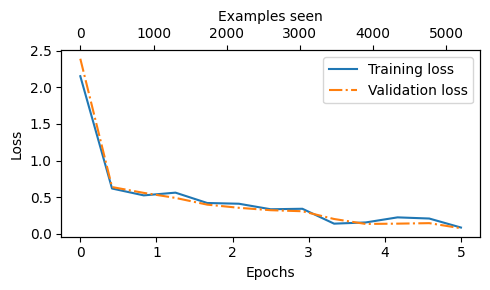

In [50]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))

plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses)

Grafik ini adalah versi run kita untuk Figure 6.16 di buku. Kedua kurva jatuh tajam di awal -- loss train turun dari 2.153 ke 0.617 dalam 50 langkah pertama -- lalu melandai sampai 0.083 untuk train dan 0.074 untuk validation. Sepanjang training kedua kurva berjalan berdampingan tanpa celah yang melebar, jadi kurva loss belum memperlihatkan tanda *overfitting* dalam lima epoch ini. Overfitting adalah keadaan ketika model menghafal data training lebih cepat daripada mempelajari pola yang juga berlaku untuk data baru; di kurva loss, ia biasanya terlihat sebagai loss validation yang berhenti turun atau malah naik, sementara loss train terus turun. Sebentar lagi kita akan melihat celah kecil antara akurasi train dan test pada seluruh data. Itu ukuran yang berbeda: satu angka di akhir training, bukan celah yang melebar dari epoch ke epoch.

Sumbu atas, `Examples seen`, memetakan 0 sampai 5 epoch ke 0 sampai 5,200 contoh. Posisi titik di sumbu x hanya perkiraan: `torch.linspace` menyebar ke-13 titik evaluasi secara merata dari 0 sampai 5, sehingga titik terakhir (langkah 600) digambar di epoch 5.0, padahal ia diukur sesudah 601 update, sekitar epoch 4.6.

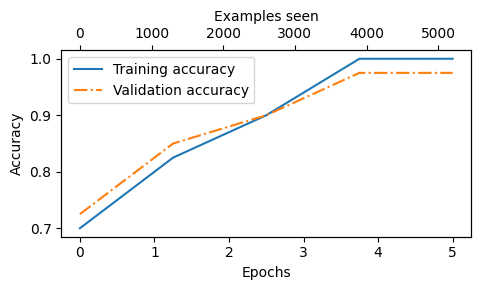

In [51]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_accs))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_accs))

plot_values(epochs_tensor, examples_seen_tensor, train_accs, val_accs, label="accuracy")

Grafik akurasi, versi run kita untuk Figure 6.17, hanya punya lima titik, satu per epoch, masing-masing dari 40 contoh. Akurasi train mencapai 100% di epoch 4, dan validation berhenti di 97.50%. Perhatikan juga sumbu x-nya: `linspace` menempatkan akurasi akhir epoch 1 di posisi 0, sehingga kurva ini tampak dimulai sebelum training sama sekali. Dengan hanya 40 contoh per titik, grafik ini sekadar indikator kasar. Angka yang sebenarnya dihitung di sel berikut, pada seluruh data.

In [52]:
train_accuracy = calc_accuracy_loader(train_loader, model, device)
val_accuracy = calc_accuracy_loader(val_loader, model, device)
test_accuracy = calc_accuracy_loader(test_loader, model, device)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 97.21%
Validation accuracy: 97.32%
Test accuracy: 95.67%


Pada seluruh data, akurasinya 97.21% untuk train, 97.32% untuk validation, dan 95.67% untuk test, sama dengan buku. Dalam jumlah pesan: 1,011 dari 1,040 contoh train (130 batch penuh; 5 pesan dibuang oleh `drop_last`), 145 dari 149 pesan validation, dan 287 dari 300 pesan test.

Selisih train dan test 1.54 poin persen, sekitar 4.6 pesan test. Buku membaca selisih ini sebagai tanda overfitting yang ringan. Validation juga sedikit di atas test, dan buku menjelaskannya dengan hyperparameter yang biasanya dipilih berdasarkan validation set. Kedua tafsiran itu masuk akal, tapi penjelasan yang lebih sederhana pun sudah cukup, yaitu ukuran sampel. Satu pesan test bernilai 0.33 poin persen dan satu pesan validation 0.67 poin, sehingga selisih 1.65 poin antara validation dan test hanya setara sekitar 2.5 pesan validation, atau 5 pesan test. Selisih sebesar beberapa pesan seperti ini bisa muncul karena kebetulan saja, jadi data ini tidak bisa memastikan tafsiran mana yang benar.

Angka 95.67% itu masih perlu dipilah. Di 6.2 kita melihat bahwa 37 baris test punya kembaran persis di train, jadi sel berikut menghitung akurasi kedua kelompok baris itu secara terpisah.

In [53]:

# Akurasi test dipisah: baris yang teksnya juga ada di train vs baris yang teksnya tidak ada di train
in_train = torch.tensor(test_df["Text"].isin(set(train_df["Text"])).tolist())
y_test_rows = torch.tensor(test_df["Label"].tolist())
model.eval()
with torch.no_grad():
    preds = torch.cat([
        model(torch.stack([test_dataset[j][0] for j in range(s, min(s + 8, len(test_dataset)))]).to(device))[:, -1, :]
        .argmax(dim=-1).cpu()
        for s in range(0, len(test_dataset), 8)
    ])
for name, mask in [("teks juga ada di train", in_train), ("teks tidak ada di train", ~in_train),
                   ("semua baris test", torch.ones_like(in_train))]:
    acc = (preds[mask] == y_test_rows[mask]).float().mean().item()
    print(f"{name:24s}: {int(mask.sum()):3d} baris | benar {int((preds[mask] == y_test_rows[mask]).sum()):3d} | akurasi {acc * 100:6.2f}%")


teks juga ada di train  :  37 baris | benar  37 | akurasi 100.00%
teks tidak ada di train : 263 baris | benar 250 | akurasi  95.06%
semua baris test        : 300 baris | benar 287 | akurasi  95.67%


Pada 37 baris test yang teksnya juga ada di train, model benar semuanya. Pada 263 baris yang teksnya tidak ada di train, akurasinya 95.06%: ke-13 kesalahan model seluruhnya ada di kelompok ini. Baris ketiga menghitung ulang 95.67% lewat jalur yang terpisah, tanpa `DataLoader`, dan hasilnya sama.

Angka 95.06% inilah yang paling dekat dengan akurasi pada pesan yang belum pernah dilihat model. Selisihnya dengan 95.67% memang kecil, tapi arahnya jelas: duplikat di pembagian buku sedikit membantu angka akhirnya.

Model sudah benar untuk sebagian besar pesan. Bagian berikut membuka model itu untuk melihat apa yang sebenarnya berubah di dalamnya.

### Under the hood 2 -- apa yang sebenarnya diubah fine-tuning

Buku menyatakan bahwa hanya block terakhir, LayerNorm terakhir, dan head yang dilatih, sedangkan sisanya beku. Apakah "beku" berarti benar-benar tidak berubah, atau hanya berubah sedikit? Dan kalau block terakhir pun hanya bergeser sedikit, bagaimana model bisa berubah dari menjawab "spam" untuk semua pesan menjadi benar untuk 95.67% pesan test?

Sel berikut membandingkan bobot model sesudah training dengan `params`, yaitu bobot pretrained yang dibaca dari checkpoint OpenAI di 6.4 dan masih tersimpan di memori sebagai array NumPy yang tidak pernah disentuh optimizer. Untuk beberapa matriks, ia menghitung perubahan relatif: norma selisih bobot akhir dan bobot awal, dibagi norma bobot awal. Sel yang sama juga membuka isi state optimizer AdamW.

In [54]:

# Under the hood 2 -- bobot sebelum/sesudah fine-tuning dan isi state AdamW
import numpy as np

def rel_change(before, after):
    before = torch.as_tensor(np.ascontiguousarray(before), dtype=torch.float32)
    after = after.detach().cpu()
    return ((after - before).norm() / before.norm()).item()

blk = params["blocks"]
rows = []
for b in (0, 5, 10, 11):
    q_w = np.split(blk[b]["attn"]["c_attn"]["w"], 3, axis=-1)[0].T
    rows.append((f"trf_blocks[{b}].att.W_query.weight", rel_change(q_w, model.trf_blocks[b].att.W_query.weight)))
    rows.append((f"trf_blocks[{b}].ff.layers[0].weight", rel_change(blk[b]["mlp"]["c_fc"]["w"].T, model.trf_blocks[b].ff.layers[0].weight)))
rows.append(("tok_emb.weight", rel_change(params["wte"], model.tok_emb.weight)))
rows.append(("final_norm.scale", rel_change(params["g"], model.final_norm.scale)))
for name, rc in rows:
    print(f"{name:38s} ||W_akhir - W_pretrained|| / ||W_pretrained|| = {rc:.6f}")

frozen_equal = all(
    torch.equal(p.detach().cpu(), torch.as_tensor(np.ascontiguousarray(ref)))
    for p, ref in [(model.tok_emb.weight, params["wte"]), (model.pos_emb.weight, params["wpe"])]
)
print("embedding beku identik bitwise dengan pretrained:", frozen_equal)

state_tensors = sum(len(s) for s in optimizer.state.values())
state_numel = sum(t.numel() for s in optimizer.state.values() for t in s.values() if t.dim() > 0)
n_params_group = sum(p.numel() for g in optimizer.param_groups for p in g["params"])
print(f"param di optimizer.param_groups : {n_params_group:,} (semua parameter model, termasuk yang beku)")
print(f"param yang punya state AdamW    : {sum(p.numel() for p in optimizer.state):,} ({len(optimizer.state)} tensor)")
print(f"state AdamW (exp_avg + exp_avg_sq): {state_numel:,} angka = {state_numel * 4 / 2**20:.1f} MB float32")
print(f"step per tensor                 : {sorted({int(s['step'].item()) for s in optimizer.state.values()})}")
w_end = model.out_head.weight.detach().cpu()
print(f"||w_spam - w_ham|| head         : awal {W_DIFF_INIT:.3f} (UTH 1) -> akhir {(w_end[1] - w_end[0]).norm():.3f}")


trf_blocks[0].att.W_query.weight       ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.000000
trf_blocks[0].ff.layers[0].weight      ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.000000
trf_blocks[5].att.W_query.weight       ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.000000
trf_blocks[5].ff.layers[0].weight      ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.000000
trf_blocks[10].att.W_query.weight      ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.000000
trf_blocks[10].ff.layers[0].weight     ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.000000
trf_blocks[11].att.W_query.weight      ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.034701
trf_blocks[11].ff.layers[0].weight     ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.025821
tok_emb.weight                         ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.000000
final_norm.scale                       ||W_akhir - W_pretrained|| / ||W_pretrained|| = 0.003315
embedding beku identik bitwise dengan pr

Block 0, 5, dan 10 berubah tepat 0.000000, dan kedua embedding identik sampai bit terakhir dengan bobot pretrained. **Beku berarti tidak bergeser sama sekali, bukan sekadar bergeser sedikit.** Tapi mekanismenya tidak otomatis. Optimizer dibuat dengan `model.parameters()`, jadi semua 124,441,346 parameter, termasuk yang beku, ada di daftar `param_groups`-nya. Yang menjaga bobot beku adalah dua hal: `requires_grad=False` membuat `.grad`-nya tetap `None`, dan AdamW melewati parameter tanpa gradien sepenuhnya, termasuk weight decay-nya. Seandainya gradiennya berisi nol alih-alih `None`, AdamW tetap memprosesnya, dan weight decay akan menggeser bobot itu sedikit demi sedikit.

Block 11 bergeser 0.0347 di `W_query` dan 0.0258 di lapisan feed-forward pertamanya, relatif terhadap besar bobot pretrained; LayerNorm terakhir bergeser 0.0033. Perubahan beberapa persen di satu block ternyata cukup. Ingat bahwa di Under the hood 1, vektor yang dibaca head hampir identik untuk semua pesan; sesudah training, vektor itu harus bisa dipisahkan menurut kelasnya. Head sendiri tidak banyak membesar: panjang selisih kedua baris bobotnya hanya naik dari 0.846 ke 0.879. Pengukuran ini tidak memisahkan peran setiap bagian, tapi tabel repo yang kita kutip di 6.5 memberi petunjuk: kalau hanya head yang dilatih, akurasinya 72.00%, dan kalau block terakhir ikut dilatih, 95.00%. Pergeseran beberapa persen di block 11 itulah yang tampaknya mengubah vektor di posisi terakhir, dari hampir seragam untuk semua pesan menjadi ringkasan yang bisa dipisahkan oleh head.

State AdamW hanya ada untuk 7,090,946 parameter dalam 20 tensor -- tepat parameter yang kita buka di 6.5. Setiap parameter itu membawa dua buffer: `exp_avg`, rata-rata berjalan gradiennya, dan `exp_avg_sq`, rata-rata berjalan kuadrat gradiennya. Dari keduanya AdamW menentukan arah dan besar langkah untuk setiap bobot. Bersama-sama, kedua buffer berisi 14,181,892 angka, atau 54.1 MB dalam float32. (Output ini menghitung 1 MB sebagai $2^{20}$ byte; hitungan memori berikutnya memakai cara yang sama, dengan 1 GB = $2^{30}$ byte.) Setiap tensor tercatat sudah menjalani 650 langkah, yaitu 5 epoch x 130 batch. Fine-tuning seluruh model (Exercise 6.2) membutuhkan state untuk 124 juta parameter, sekitar 0.93 GB untuk kedua buffer itu saja, belum termasuk gradiennya.

## 6.8 Using the LLM as a spam classifier

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/06.Chapter06/figure6.18.png" width="700">

**Figure 6.18** Langkah 10, langkah terakhir: model yang sudah di-fine-tune dipakai untuk mengklasifikasikan pesan baru.

Model sudah dilatih, dan kini kita pakai untuk pesan yang tidak ada di dataset. `classify_review` mengulang persiapan input dari `SpamDataset` untuk satu teks -- ubah menjadi token, potong, lalu isi dengan 50256 sampai `max_length` -- kemudian mengambil argmax logit token terakhir. Versi repo terbaru berbeda dari versi cetak di satu baris, dan menambahkan dua `assert`.

In [55]:
def classify_review(text, model, tokenizer, device, max_length=None, pad_token_id=50256):
    model.eval()

    # Prepare inputs to the model
    input_ids = tokenizer.encode(text)
    supported_context_length = model.pos_emb.weight.shape[0]
    # Note: In the book, this was originally written as pos_emb.weight.shape[1] by mistake
    # It didn't break the code but would have caused unnecessary truncation (to 768 instead of 1024)

    # Truncate sequences if they too long
    input_ids = input_ids[:min(max_length, supported_context_length)]
    assert max_length is not None, (
        "max_length must be specified. If you want to use the full model context, "
        "pass max_length=model.pos_emb.weight.shape[0]."
    )
    assert max_length <= supported_context_length, (
        f"max_length ({max_length}) exceeds model's supported context length ({supported_context_length})."
    )
    # Alternatively, a more robust version is the following one, which handles the max_length=None case better
    # max_len = min(max_length,supported_context_length) if max_length else supported_context_length
    # input_ids = input_ids[:max_len]

    # Pad sequences to the longest sequence
    input_ids += [pad_token_id] * (max_length - len(input_ids))
    input_tensor = torch.tensor(input_ids, device=device).unsqueeze(0) # add batch dimension

    # Model inference
    with torch.no_grad():
        logits = model(input_tensor)[:, -1, :]  # Logits of the last output token
    predicted_label = torch.argmax(logits, dim=-1).item()

    # Return the classified result
    return "spam" if predicted_label == 1 else "not spam"

Baris yang berbeda itu adalah kesalahan pertama di kode cetak yang dicatat notebook ini, dan sel yang mengujinya diberi label Errata #1. (*Errata* adalah daftar kesalahan dalam sebuah buku cetak; untuk bab ini notebook mencatat tiga.) Buku menghitung `supported_context_length = model.pos_emb.weight.shape[1]`. Tabel embedding posisi berbentuk `[context_length, emb_dim]`, yaitu `[1024, 768]`, sehingga `shape[1]` adalah dimensi embedding (768), bukan jumlah posisi (1,024). Kodenya tetap berjalan, karena `min(max_length, 768)` sama dengan `max_length` selama `max_length` tidak lebih dari 768, dan di bab ini `max_length` hanya 120. Bug seperti ini tidak menimbulkan error; ia baru terasa ketika input-nya panjang. Repo sekarang memakai `shape[0]`.

Kedua `assert` baru tidak sama bergunanya. Yang pertama, `max_length is not None`, diletakkan sesudah baris pemotongan yang sudah memanggil `min(max_length, ...)`, sehingga `max_length=None` tetap gagal dengan `TypeError` sebelum assert itu sempat diperiksa -- perilaku yang sama dengan versi cetak. Yang benar-benar bekerja adalah assert kedua: `max_length` di atas 1,024 kini ditolak dengan pesan yang jelas.

Sel berikut menguji akibat Errata #1 secara langsung. Versi cetak dijalankan di namespace terpisah, lalu dibandingkan dengan versi repo, pada pengaturan bab dan pada teks panjang dengan `max_length=1024` (pengaturan Exercise 6.1). Sebuah *forward pre-hook* di `tok_emb`, fungsi yang dipanggil tepat sebelum lapisan itu dihitung, mencatat berapa token isi -- bukan token pengisi -- yang benar-benar masuk ke model.

In [56]:
# Errata #1 -- classify_review versi era cetak (pos_emb.weight.shape[1]) vs versi HEAD (shape[0])
BOOK_ERA_CLASSIFY = '''
def classify_review(text, model, tokenizer, device, max_length=None, pad_token_id=50256):
    model.eval()

    # Prepare inputs to the model
    input_ids = tokenizer.encode(text)
    supported_context_length = model.pos_emb.weight.shape[1]

    # Truncate sequences if they too long
    input_ids = input_ids[:min(max_length, supported_context_length)]

    # Pad sequences to the longest sequence
    input_ids += [pad_token_id] * (max_length - len(input_ids))
    input_tensor = torch.tensor(input_ids, device=device).unsqueeze(0) # add batch dimension

    # Model inference
    with torch.no_grad():
        logits = model(input_tensor)[:, -1, :]  # Logits of the last output token
    predicted_label = torch.argmax(logits, dim=-1).item()

    # Return the classified result
    return "spam" if predicted_label == 1 else "not spam"
'''
book_ns = {"torch": torch}
exec(BOOK_ERA_CLASSIFY, book_ns)
classify_review_book = book_ns["classify_review"]
print("pos_emb.weight.shape:", tuple(model.pos_emb.weight.shape))

same = sum(
    classify_review(t, model, tokenizer, device, max_length=train_dataset.max_length)
    == classify_review_book(t, model, tokenizer, device, max_length=train_dataset.max_length)
    for t in test_df["Text"]
)
print(f"setting bab (max_length={train_dataset.max_length}): prediksi identik {same}/{len(test_df)} pesan test")

long_text = " ".join(test_df["Text"].tolist()[:60])
seen = {}
hook = model.tok_emb.register_forward_pre_hook(
    lambda m, args: seen.__setitem__("n_content", int((args[0] != 50256).sum())))
for name, fn in [("HEAD  shape[0]", classify_review), ("cetak shape[1]", classify_review_book)]:
    label = fn(long_text, model, tokenizer, device, max_length=1024)
    print(f"{name}: {len(tokenizer.encode(long_text))} token teks -> {seen['n_content']} token isi "
          f"+ {1024 - seen['n_content']} padding masuk model | label {label!r}")
hook.remove()

pos_emb.weight.shape: (1024, 768)
setting bab (max_length=120): prediksi identik 300/300 pesan test
HEAD  shape[0]: 1855 token teks -> 1024 token isi + 0 padding masuk model | label 'spam'
cetak shape[1]: 1855 token teks -> 768 token isi + 256 padding masuk model | label 'spam'


Pada pengaturan bab (`max_length=120`), kedua versi memberi prediksi yang sama untuk ke-300 pesan test. Jadi bug ini tidak mengubah angka buku di mana pun.

Bedanya muncul pada teks panjang. Gabungan 60 pesan test berisi 1,855 token. Versi repo memasukkan 1,024 token isi, memenuhi seluruh konteks. Versi cetak memotong di 768 token, lalu mengisi 256 posisi sisanya dengan token pengisi, tanpa peringatan apa pun. Label kedua versi kebetulan sama untuk teks ini ('spam'), tapi input yang dilihat model berbeda. Siapa pun yang mengerjakan Exercise 6.1 dengan `classify_review` versi cetak akan menilai teks panjang dengan konteks yang diam-diam terpotong.

In [57]:
text_1 = (
    "You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award."
)

print(classify_review(
    text_1, model, tokenizer, device, max_length=train_dataset.max_length
))

spam


Model menjawab "spam". Ini pesan yang sama dengan yang di 6.4 membuat model pretrained hanya menyalin pertanyaan. Sesudah fine-tuning, model tidak lagi menulis apa-apa; ia memilih satu dari dua label. Seberapa baru pesan ini bagi model akan kita periksa sesudah contoh kedua.

In [58]:
text_2 = (
    "Hey, just wanted to check if we're still on"
    " for dinner tonight? Let me know!"
)

print(classify_review(
    text_2, model, tokenizer, device, max_length=train_dataset.max_length
))

not spam


Pesan kedua dijawab "not spam". Kedua pesan di-pad sampai `max_length=train_dataset.max_length`, yaitu 120 token. Argumen ini terlihat seperti detail kecil, tapi Under the hood 3 akan menunjukkan betapa model ini bergantung padanya.

Sebelum sampai ke sana, kita tepati dulu janji tadi: sel berikut mencari frasa kunci kedua contoh buku di dataset dan di train split.

In [59]:

# Seberapa baru dua contoh buku bagi model? Cari frasa kuncinya di dataset dan di train split
for phrase in ["specially selected", "dinner tonight"]:
    hits = df[df["Text"].str.contains(phrase, case=False)]
    in_train = train_df[train_df["Text"].str.contains(phrase, case=False)]
    print(f"{phrase!r:22} dataset: {len(hits)} pesan {hits['Label'].value_counts().to_dict()} | "
          f"train split: {len(in_train)} | teks persis contoh buku ada: "
          f"{bool((df['Text'] == (text_1 if phrase == 'specially selected' else text_2)).any())}")


'specially selected'   dataset: 8 pesan {'spam': 8} | train split: 3 | teks persis contoh buku ada: False
'dinner tonight'       dataset: 2 pesan {'ham': 2} | train split: 0 | teks persis contoh buku ada: False


Teks persis kedua contoh tidak ada di dataset. Tapi frasa kunci contoh spam, "specially selected", muncul di 8 pesan dataset, semuanya spam, dan 3 di antaranya masuk train split. Jadi model sudah pernah melihat frasa kunci contoh pertama buku saat training, selalu di pesan spam: ujian yang mudah, bukan tanda bahwa model bisa menggeneralisasi. Frasa "dinner tonight" hanya muncul di 2 pesan ham, dan tidak satu pun di train.

Dua contoh memang tidak cukup untuk menilai sebuah classifier. Ukuran yang lebih bisa dipercaya sudah kita punya dari 6.7: 95.06% pada 263 baris test yang teksnya tidak ada di train.

### Under the hood 3 -- token terakhir hampir selalu `<|endoftext|>`

Sejak 6.3 kita sudah curiga. Classifier membaca posisi terakhir tensor (`[:, -1, :]`), dan karena `SpamDataset` menaruh padding di kanan sampai 120 token, posisi terakhir itu hampir selalu berisi token pengisi, bukan kata terakhir pesan. Model tetap bisa bekerja karena token pengisi di posisi 119 boleh memperhatikan seluruh pesan di sebelah kirinya. Tapi itu berarti yang dipelajari fine-tuning sangat spesifik: ringkasan pesan yang dibaca lewat token `<|endoftext|>` di posisi 119.

Kalau itu benar, model yang sudah dilatih seharusnya peka terhadap cara input disusun. Sel berikut menghitung dulu seberapa sering posisi terakhir berisi padding, lalu menilai model terlatih yang sama -- tanpa melatih ulang -- pada 300 pesan test dengan empat cara menyusun input dan membaca output-nya.

In [60]:

# Under the hood 3 -- sensus padding + akurasi model terlatih bila cara padding/pembacaan diubah
pad = 50256
last_is_pad = sum(e[-1] == pad for e in train_dataset.encoded_texts)
n_pads = [train_dataset.max_length - len(tokenizer.encode(t)) for t in train_df["Text"]]
print(f"pesan train berakhir <|endoftext|> : {last_is_pad}/{len(train_dataset)} "
      f"| padding per pesan: median {statistics.median(n_pads):.0f}, max {max(n_pads)}")


def last_logits(texts, max_length, read):
    """max_length=None: tanpa padding (batch 1). read='last': posisi -1; 'content': token isi terakhir."""
    out_rows = []
    model.eval()
    with torch.no_grad():
        if max_length is None:
            for t in texts:
                x = torch.tensor(tokenizer.encode(t), device=device).unsqueeze(0)
                out_rows.append(model(x)[0, -1].cpu())
        else:
            for i in range(0, len(texts), 8):
                chunk = [tokenizer.encode(t)[:max_length] for t in texts[i:i + 8]]
                x = torch.tensor([ids + [pad] * (max_length - len(ids)) for ids in chunk], device=device)
                pos = [len(ids) - 1 if read == "content" else max_length - 1 for ids in chunk]
                out_rows.extend(model(x)[torch.arange(len(chunk)), torch.tensor(pos)].cpu())
    return torch.stack(out_rows)


texts, labels = test_df["Text"].tolist(), torch.tensor(test_df["Label"].tolist())
settings_uth3 = [("pad 120, baca posisi 119 (= training)", 120, "last"),
                 ("pad 120, baca token isi terakhir", 120, "content"),
                 ("tanpa padding, baca posisi terakhir", None, "last"),
                 ("pad 1024, baca posisi 1023", 1024, "last")]
UTH3 = {}
for name, max_len, read in settings_uth3:
    z = last_logits(texts, max_len, read)
    UTH3[name] = z
    pred = z.argmax(dim=-1)
    print(f"{name:40s} test acc {(pred == labels).float().mean() * 100:6.2f}% | prediksi spam {pred.float().mean() * 100:5.1f}%")

z_content, z_nopad = UTH3[settings_uth3[1][0]], UTH3[settings_uth3[2][0]]
print(f"causal mask: logit token isi terakhir, pad 120 vs tanpa padding -> max |selisih| {(z_content - z_nopad).abs().max():.2e}")


pesan train berakhir <|endoftext|> : 1044/1045 | padding per pesan: median 88, max 118
pad 120, baca posisi 119 (= training)    test acc  95.67% | prediksi spam  48.0%
pad 120, baca token isi terakhir         test acc  50.33% | prediksi spam 100.0%
tanpa padding, baca posisi terakhir      test acc  50.33% | prediksi spam 100.0%
pad 1024, baca posisi 1023               test acc  50.33% | prediksi spam 100.0%
causal mask: logit token isi terakhir, pad 120 vs tanpa padding -> max |selisih| 9.78e-06


Hampir semua: 1,044 dari 1,045 pesan training berakhir dengan `<|endoftext|>`. Satu-satunya pengecualian adalah pesan terpanjang, yang tepat 120 token. Median padding-nya 88 token per pesan. Jadi selama training, head hampir selalu membaca hidden state milik sebuah token pengisi.

Hasil keempat cara membaca itu jauh lebih mencolok daripada dugaan kita. Dengan input yang disusun persis seperti saat training, model mencapai 95.67%, dan 48.0% pesan diprediksi spam, dekat dengan porsi spam sebenarnya di test set. Tiga cara lain -- membaca token isi terakhir, yang secara intuitif paling informatif; tanpa padding sama sekali; dan padding sampai 1,024 token, pengaturan Exercise 6.1 tanpa melatih ulang -- semuanya jatuh ke 50.33%, dengan 100.0% pesan diprediksi spam. Angka 50.33% itu adalah porsi spam di test set, jadi model kembali ke perilaku head acak di Under the hood 1: satu jawaban untuk semua pesan. **Fine-tuning tidak mengajari model "membaca SMS" secara umum; ia memisahkan kedua kelas di satu titik representasi, yaitu token `<|endoftext|>` di posisi 119.**

Baris terakhir menguji causal mask. Logit di token isi terakhir hampir identik antara input yang di-pad dan yang tidak; selisih terbesarnya 9.78e-06. Padding di kanan memang tidak bisa memengaruhi posisi di kirinya. Selisih kecil yang tersisa kemungkinan besar berasal dari pembulatan float32: GPU menjumlahkan angka dalam urutan yang sedikit berbeda untuk tensor yang panjangnya berbeda (120 token, dibanding sepanjang pesannya saja). Jadi yang berubah karena padding hanyalah *posisi yang dibaca*, dan itu saja sudah cukup untuk menjatuhkan akurasi dari 95.67% ke 50.33%.

Konsekuensi praktisnya: `max_length` dan arah padding adalah bagian dari syarat input model ini, sama pentingnya dengan tokenizer. Itulah sebabnya `classify_review` harus diberi `max_length=train_dataset.max_length`; `max_length=None` tidak didukung di kedua versi, karena keduanya gagal dengan `TypeError` dari `min(None, ...)`. Alternatif yang lebih tahan adalah *melatih* model sambil membaca token isi terakhir. Tabel eksperimen tambahan di repo resmi (`--trainable_token_pos flexible`) melaporkan akurasi test 98.33% untuk cara itu, dibanding 95.00% untuk pengaturan bab pada skrip yang sama; angka itu dari repo, bukan dari run ini.

In [61]:
torch.save(model.state_dict(), "review_classifier.pth")

`torch.save(model.state_dict(), ...)` menyimpan seluruh state model: 124,441,346 parameter float32, termasuk 11 block beku yang sama persis dengan GPT-2 asli, ditambah 12 buffer `mask` berukuran 1,024 x 1,024. Dihitung dengan cara yang sama seperti di Under the hood 2, isinya sekitar 523 MB, padahal yang berubah hanya 7,090,946 parameter, sekitar 27 MB. Menyimpan parameter yang dilatih saja, ditambah keterangan bobot pretrained mana yang dipakai, sebenarnya sudah cukup untuk membangun ulang model ini. Buku memilih cara yang paling sederhana.

Untuk memuat kembali model yang tersimpan, buku mencetak baris berikut. Sel ini menjalankannya persis seperti tercetak, di dalam `try/except`, supaya error-nya tercetak tanpa menghentikan notebook.

In [62]:
# Errata #2 -- baris pemuatan model seperti tercetak di buku, lewat harness
import traceback

LISTING = '''
model_state_dict = torch.load("review_classifier.pth, map_location=device")
model.load_state_dict(model_state_dict)
'''

try:
    exec(LISTING)
except Exception as e:
    traceback.print_exception(type(e), e, e.__traceback__.tb_next, limit=1, chain=False)

Traceback (most recent call last):
  File "<string>", line 2, in <module>
FileNotFoundError: [Errno 2] No such file or directory: 'review_classifier.pth, map_location=device'


Inilah Errata #2. Di versi cetak, tanda kutip penutup nama file jatuh sesudah `map_location=device`, sehingga seluruh `"review_classifier.pth, map_location=device"` menjadi satu string nama file. `torch.load` mencari file dengan nama itu, tidak menemukannya, lalu berhenti dengan `FileNotFoundError`; `map_location` tidak pernah sampai sebagai argumen. Repo sudah menulis baris ini dengan benar sejak buku terbit, dan versi terbarunya menambahkan `weights_only=True`.

In [63]:
model_state_dict = torch.load("review_classifier.pth", map_location=device, weights_only=True)
model.load_state_dict(model_state_dict)

<All keys matched successfully>

`<All keys matched successfully>` berarti setiap key di file cocok dengan arsitektur model sekarang, yang head-nya berisi 2 kelas. `weights_only=True` membatasi pembacaan file hanya ke tensor dan tipe data sederhana, sehingga file `.pth` dari sumber yang tidak dikenal tidak bisa menjalankan kode saat dimuat. Sejak PyTorch 2.6 ini menjadi perilaku bawaan, jadi di torch 2.11.0 argumen ini hanya mempertegasnya.

## Exercises

Ketiga latihan bab ini masing-masing mengubah satu keputusan yang sudah kita ukur: panjang padding (Exercise 6.1; Under the hood 3 menunjukkan betapa menentukannya posisi yang dibaca classifier), bagian model yang dilatih (Exercise 6.2; Under the hood 2 menunjukkan apa yang berubah ketika hanya satu block dilatih), dan token yang dibaca (Exercise 6.3).

Ketiganya butuh training ulang dari bobot pretrained. Sel-sel berikut menyiapkan satu fungsi, `run_classifier_experiment`, yang mengulang listing 6.4 sampai 6.10 apa adanya -- dataset, data loader, `GPTModel` dengan bobot pretrained, pembekuan, head baru dengan seed 123, `train_classifier_simple` dengan hyperparameter dan seed yang sama, lalu akurasi pada seluruh data -- dengan tepat satu perubahan per latihan, mengikuti `exercise-solutions.ipynb` di repo. Untuk Exercise 6.3 ada `FirstTokenView`, pembungkus yang hanya meneruskan output posisi 0, sehingga setiap `[:, -1, :]` di fungsi bab membaca token pertama. Hasilnya setara dengan instruksi solusi resmi, "ganti `[:, -1, :]` dengan `[:, 0, :]` di semua kode", tanpa menulis ulang fungsi bab.

Training tambahan ini dijaga oleh beberapa sakelar yang secara bawaan bernilai `False`, supaya *Run all* tidak melatih ulang model, termasuk di mesin tanpa GPU. Di run ini semua sakelar itu tetap `False`, jadi training untuk kontrol dan ketiga latihan tidak dijalankan, dan tidak ada angka hasil latihan dari run ini. Pesan yang dicetak sel-sel itu merujuk ke output run lain, yang tidak ikut tersimpan di notebook ini. Untuk menjalankan latihan, ubah sakelarnya menjadi `True`. Tanpa training pun, ada yang tetap bisa kita lakukan: membaca setiap latihan dengan bantuan hasil Under the hood, dan menjalankan satu analisis ringan untuk Exercise 6.3.

In [64]:
# Guard training tambahan (latihan + Under the hood 4). Default False supaya Run All -- juga di CPU --
# tidak melatih ulang. Output di bawah sel-sel ber-guard adalah replay run builder dengan guard = True.
RUN_EXERCISE_CONTROL = False   # helper dengan setting bab: harus identik dengan listing 6.10
RUN_EXERCISE_6_1 = False       # padding ke 1024 token
RUN_EXERCISE_6_2 = False       # seluruh model trainable
RUN_EXERCISE_6_3 = False       # token pertama, bukan terakhir
RUN_UTH4_CPU_TRAINING = False  # listing 6.10 diulang di CPU untuk Under the hood 4
EXERCISE_RESULTS = {}

In [65]:
import gc
import time


class FirstTokenView(torch.nn.Module):
    """Hanya meneruskan output posisi 0, sehingga setiap `[:, -1, :]` di fungsi bab membaca token pertama."""

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, in_idx):
        return self.model(in_idx)[:, :1, :]


def run_classifier_experiment(name, max_length=None, trainable="last_block", token="last", num_epochs=5, dev=None):
    """Ulangi listing 6.4-6.10 dari bobot pretrained segar dengan tepat satu perubahan."""
    dev = device if dev is None else dev
    t0 = time.time()
    # data: SpamDataset + DataLoader persis seperti listing 6.4 dan 6.5
    train_ds = SpamDataset(csv_file="train.csv", max_length=max_length, tokenizer=tokenizer)
    val_ds = SpamDataset(csv_file="validation.csv", max_length=train_ds.max_length, tokenizer=tokenizer)
    test_ds = SpamDataset(csv_file="test.csv", max_length=train_ds.max_length, tokenizer=tokenizer)
    torch.manual_seed(123)
    tr_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0, drop_last=True)
    va_loader = DataLoader(val_ds, batch_size=8, num_workers=0, drop_last=False)
    te_loader = DataLoader(test_ds, batch_size=8, num_workers=0, drop_last=False)
    # model: listing 6.6 + 6.7 dari `params` pretrained (bukan model yang sudah di-fine-tune di atas)
    m = GPTModel(BASE_CONFIG)
    load_weights_into_gpt(m, params)
    m.eval()
    if trainable != "all":
        for param in m.parameters():
            param.requires_grad = False
    torch.manual_seed(123)
    m.out_head = torch.nn.Linear(in_features=BASE_CONFIG["emb_dim"], out_features=num_classes)
    for param in m.trf_blocks[-1].parameters():
        param.requires_grad = True
    for param in m.final_norm.parameters():
        param.requires_grad = True
    m.to(dev)
    net = FirstTokenView(m) if token == "first" else m
    # training: listing 6.10, hyperparameter dan seed sama
    torch.manual_seed(123)
    optimizer = torch.optim.AdamW(net.parameters(), lr=5e-5, weight_decay=0.1)
    train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
        net, tr_loader, va_loader, optimizer, dev,
        num_epochs=num_epochs, eval_freq=50, eval_iter=5,
    )
    acc = {split: calc_accuracy_loader(loader, net, dev)
           for split, loader in (("train", tr_loader), ("val", va_loader), ("test", te_loader))}
    minutes = (time.time() - t0) / 60
    n_trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"[{name}] max_length={train_ds.max_length}, trainable={trainable} ({n_trainable:,} params), token={token}")
    print(f"[{name}] Training accuracy: {acc['train']*100:.2f}% | Validation accuracy: {acc['val']*100:.2f}% | "
          f"Test accuracy: {acc['test']*100:.2f}% | {minutes:.2f} min on {dev}")
    EXERCISE_RESULTS[name] = {"acc": acc, "minutes": minutes, "n_trainable": n_trainable,
                              "max_length": train_ds.max_length, "train_losses": train_losses,
                              "val_losses": val_losses, "train_accs": train_accs, "val_accs": val_accs,
                              "device": str(dev)}
    del m, net, optimizer
    gc.collect()
    if dev.type == "mps":
        torch.mps.empty_cache()
    return EXERCISE_RESULTS[name]

Sel pertama adalah kontrol: fungsi tadi dengan pengaturan bab, tanpa perubahan apa pun. Kalau fungsi itu benar-benar setara dengan listing 6.4 sampai 6.10, log dan akurasinya harus identik dengan training di 6.7. Kontrol inilah yang memungkinkan setiap selisih di latihan dibaca sebagai akibat dari satu perubahan yang disebut, bukan dari fungsinya.

In [66]:
# Kontrol: helper dengan setting bab. Log harus identik dengan output listing 6.10 di atas.
if RUN_EXERCISE_CONTROL:
    run_classifier_experiment("control")
else:
    print("RUN_EXERCISE_CONTROL = False -> dilewati (output di bawah: replay builder)")

RUN_EXERCISE_CONTROL = False -> dilewati (output di bawah: replay builder)


Karena itu, kesetaraan fungsi ini dengan listing 6.10 belum teruji. Kalau `RUN_EXERCISE_CONTROL` dinyalakan, yang perlu diperiksa adalah 18 baris log yang sama dengan 6.7 dan akurasi akhir 97.21%, 97.32%, dan 95.67%. Baru sesudah kontrol itu cocok, angka ketiga latihan bisa dibandingkan dengan aman terhadap run utama.

### Exercise 6.1 -- padding ke 1,024 token

Satu perubahan: `max_length = BASE_CONFIG["context_length"]` untuk train, validation, dan test, sehingga setiap pesan diisi sampai 1,024 token. Input menjadi sekitar 8.5 kali lebih panjang (1,024 dibanding 120), dan karena matriks skor attention tumbuh dengan kuadrat panjang input, matriks itu di setiap lapisan menjadi sekitar 73 kali lebih besar.

In [67]:
# Exercise 6.1 -- pad semua input ke panjang konteks maksimum model (exercise-solutions.ipynb:
# max_length = BASE_CONFIG["context_length"] untuk train, validation, dan test)
if RUN_EXERCISE_6_1:
    run_classifier_experiment("ex6.1", max_length=BASE_CONFIG["context_length"])
else:
    print("RUN_EXERCISE_6_1 = False -> dilewati (output di bawah: replay builder)")

RUN_EXERCISE_6_1 = False -> dilewati (output di bawah: replay builder)


Solusi resmi melaporkan akurasi test 78.33% untuk eksperimen ini. Angka itu berasal dari skrip eksperimen terpisah di repo (`additional_experiments.py`), yang untuk pengaturan bab memberi 95.00%, bukan 95.67%, jadi yang bisa dibandingkan adalah arah dan besarnya penurunan, sekitar 17 poin, bukan angka absolutnya.

Under the hood 3 memberi petunjuk kenapa penurunan itu masuk akal. Model yang kita latih dengan padding 120 jatuh ke 50.33% begitu diberi padding 1,024 tanpa dilatih ulang. Melatih ulang dengan 1,024 token memberi model kesempatan untuk menyesuaikan diri, tapi tugasnya jauh lebih sulit: token yang dibaca classifier kini berjarak sekitar seribu posisi dari isi pesan, dan hampir seluruh konteks yang bisa ia perhatikan adalah token `<|endoftext|>` yang identik. Sinyal dari isi pesan tenggelam di antara token pengisi, dan hanya ada satu block yang bisa dilatih untuk mengangkatnya kembali. Ini penjelasan yang masuk akal untuk angka solusi resmi, tapi tidak diuji di run ini.

### Exercise 6.2 -- fine-tuning seluruh model

Satu perubahan: loop yang membekukan parameter (`param.requires_grad = False`) dihapus, sehingga semua 124 juta parameter ikut dilatih.

In [68]:
# Exercise 6.2 -- fine-tune seluruh model: loop `requires_grad = False` dihapus (exercise-solutions.ipynb)
if RUN_EXERCISE_6_2:
    run_classifier_experiment("ex6.2", trainable="all")
else:
    print("RUN_EXERCISE_6_2 = False -> dilewati (output di bawah: replay builder)")

RUN_EXERCISE_6_2 = False -> dilewati (output di bawah: replay builder)


Dengan seluruh model ikut dilatih, solusi resmi melaporkan akurasi test 96.67%. Angka ini berasal dari skrip yang sama dengan Exercise 6.1, dan hasilnya juga tercatat di tabel eksperimen tambahan yang kita kutip di 6.5. Di tabel itu pengaturan bab mendapat 95.00%, jadi kenaikannya sekitar 1.7 poin, kira-kira lima pesan test. (Solusi resmi sendiri membandingkannya dengan 95.67% di bab utama dan menyebutnya kenaikan sekitar satu poin.) Selisih beberapa pesan dari satu kali training seperti ini adalah kenaikan yang kecil, bukan lompatan.

Under the hood 2 sudah memberi gambaran harganya. Parameter yang dilatih menjadi 17.5 kali lebih banyak (124,441,346 dibanding 7,090,946), state AdamW membengkak menjadi sekitar 0.93 GB alih-alih 54.1 MB, dan backpropagation harus menembus 12 block, bukan satu. Kenaikan akurasi sekecil itu sejalan dengan alasan buku membekukan sebagian besar model: representasi pretrained di block-block bawah sudah cukup umum untuk tugas ini, dan yang paling perlu disesuaikan adalah ujung atas jaringan.

### Exercise 6.3 -- token pertama vs token terakhir

Satu perubahan: classifier membaca output posisi 0 lewat `FirstTokenView`, bukan posisi terakhir.

In [69]:
# Exercise 6.3 -- latih token output pertama: setara mengganti [:, -1, :] menjadi [:, 0, :] di semua fungsi
if RUN_EXERCISE_6_3:
    run_classifier_experiment("ex6.3", token="first")
else:
    print("RUN_EXERCISE_6_3 = False -> dilewati (output di bawah: replay builder)")

RUN_EXERCISE_6_3 = False -> dilewati (output di bawah: replay builder)


Di sini angka solusi resmi jauh lebih rendah: 75.00%, sekitar 20 poin di bawah pengaturan bab. Untuk latihan ini, kita bahkan tidak perlu melatih apa pun untuk memahami kenapa.

Ingat causal mask di 6.5: output di posisi 0 hanya bisa bergantung pada token pertama pesan. Berapa pun bobotnya, seluruh model, dengan 12 block-nya, tereduksi menjadi fungsi dari satu token ID. Kalau begitu, classifier yang paling banyak benar di train set, selama hanya boleh melihat token pertama, adalah sebuah tabel sederhana: untuk setiap token pertama, jawab dengan label yang paling sering muncul bersamanya di train set. Sel berikut membangun tabel itu tanpa training sama sekali.

In [70]:

# Exercise 6.3 -- classifier terbaik yang mungkin dari token pertama saja (lookup label mayoritas)
from collections import Counter, defaultdict

def first_token(text):
    return tokenizer.encode(text)[0]

votes = defaultdict(Counter)
for text, y in zip(train_df["Text"], train_df["Label"]):
    votes[first_token(text)][y] += 1
majority = {tok: c.most_common(1)[0][0] for tok, c in votes.items()}
fallback = int(train_df["Label"].mean() >= 0.5)

for name, frame in [("train", train_df), ("validation", validation_df), ("test", test_df)]:
    preds = [majority.get(first_token(t), fallback) for t in frame["Text"]]
    unseen = sum(first_token(t) not in majority for t in frame["Text"])
    acc = sum(p == y for p, y in zip(preds, frame["Label"])) / len(frame)
    print(f"{name:>10}: lookup acc {acc * 100:6.2f}% | token pertama tak terlihat di train: {unseen}/{len(frame)}")
print(f"token pertama unik di train: {len(majority)} | contoh: "
      + ", ".join(f"{tokenizer.decode([t])!r}->{'spam' if majority[t] else 'ham'}"
                  for t, _ in Counter(first_token(t) for t in train_df['Text']).most_common(5)))


     train: lookup acc  89.19% | token pertama tak terlihat di train: 0/1045
validation: lookup acc  75.84% | token pertama tak terlihat di train: 30/149
      test: lookup acc  77.67% | token pertama tak terlihat di train: 53/300
token pertama unik di train: 334 | contoh: 'I'->ham, 'You'->spam, 'UR'->spam, 'Ur'->spam, 'Free'->spam


Tabel itu berisi 334 token pertama yang berbeda, dan lima yang paling sering sudah memperlihatkan polanya: pesan yang dibuka dengan "I" biasanya ham, sedangkan "You", "UR", "Ur", dan "Free" biasanya spam. Dengan tabel itu saja, akurasinya 89.19% di train, 75.84% di validation, dan 77.67% di test.

Angka train itu punya arti khusus. Untuk fungsi apa pun yang hanya melihat token pertama, memilih label mayoritas per token adalah pilihan terbaik di data training, jadi **89.19% adalah batas atas akurasi train untuk classifier token pertama mana pun**, termasuk GPT-2 lengkap yang dilatih lewat `FirstTokenView`. Di validation dan test, tabel ini turun ke kisaran 76 sampai 78%, sebagian karena 30 dari 149 pesan validation dan 53 dari 300 pesan test dibuka dengan token yang tidak pernah membuka pesan train, sehingga tabel terpaksa memakai jawaban cadangan. Akurasi test 75.00% di solusi resmi berada di kisaran yang sama.

Inilah kebalikan dari Under the hood 3. Di sana, posisi terakhir bisa memperhatikan seluruh pesan, dan fine-tuning memanfaatkannya. Di sini, sebanyak apa pun lapisan transformer tidak bisa menambah informasi kalau yang bisa mereka lihat hanya satu token.

### Under the hood 4 -- GPU vs CPU vs buku

Buku dicetak dari run di CPU, sedangkan run ini berjalan di GPU, dan log training di 6.7 tetap sama sampai tiga desimal di setiap titik. Tapi tiga desimal bisa menyembunyikan perbedaan. Notebook ini menyiapkan dua pengukuran: (a) model terlatih yang sama dijalankan di GPU dan di CPU, lalu logit dan prediksinya dibandingkan; (b) seluruh training bab diulang di CPU, lalu keempat kurvanya dibandingkan dengan run GPU pada presisi penuh. Pengukuran (a) murah dan berjalan di run ini; pengukuran (b) butuh training ulang, dan sakelarnya dimatikan.

In [71]:

# Under the hood 4a -- model terlatih yang sama: logit token terakhir di CPU vs device notebook
if device.type == "cpu":
    print("device notebook = cpu: tidak ada device kedua untuk dibandingkan")
else:
    model.eval()
    with torch.no_grad():
        z_dev = torch.cat([model(xb.to(device))[:, -1, :].cpu() for xb, _ in test_loader])
        model.to("cpu")
        z_cpu = torch.cat([model(xb)[:, -1, :] for xb, _ in test_loader])
        model.to(device)
    y_test = torch.cat([yb for _, yb in test_loader])
    diff = (z_dev - z_cpu).abs()
    print(f"logit 300 x 2: max |{device.type} - cpu| = {diff.max():.3e}, median {diff.median():.3e}, "
          f"identik bitwise {(diff == 0).float().mean() * 100:.1f}%")
    print(f"skala logit: max |z| = {z_cpu.abs().max():.2f} -> selisih relatif ~{diff.max() / z_cpu.abs().max():.1e}")
    print(f"prediksi berbeda: {(z_dev.argmax(-1) != z_cpu.argmax(-1)).sum().item()} dari {len(y_test)} | "
          f"test acc {device.type} {(z_dev.argmax(-1) == y_test).float().mean() * 100:.2f}% vs "
          f"cpu {(z_cpu.argmax(-1) == y_test).float().mean() * 100:.2f}%")


logit 300 x 2: max |cuda - cpu| = 1.502e-05, median 2.384e-06, identik bitwise 2.0%
skala logit: max |z| = 4.35 -> selisih relatif ~3.5e-06
prediksi berbeda: 0 dari 300 | test acc cuda 95.67% vs cpu 95.67%


Untuk model yang sama persis, GPU dan CPU menghasilkan logit yang berbeda: selisih terbesarnya 1.502e-05, mediannya 2.384e-06, dan hanya 2.0% dari 600 logit yang identik sampai bit terakhir. Penyebab yang paling mungkin sama dengan selisih kecil di Under the hood 3: kernel perkalian matriks di GPU dan di CPU menjumlahkan angka float32 dalam urutan yang berbeda, sehingga pembulatan terakhirnya pun berbeda.

Seberapa besar selisih itu? Logit terbesar bernilai 4.35, jadi selisih relatifnya di orde 3.5e-06. Selisih sekecil itu ternyata tidak membalik satu keputusan pun: dari 300 prediksi, tidak ada yang berubah, dan akurasi test sama di kedua device, 95.67%. Tapi pengukuran ini hanya melihat satu forward pass dari model yang sudah jadi. Selama training, selisih sekecil ini muncul di setiap langkah dan bisa ikut terbawa ke langkah berikutnya; itulah yang ingin dijawab oleh pengukuran (b).

In [72]:
# Under the hood 4b -- pipeline bab yang sama (lewat helper, terbukti identik dengan listing 6.10) di CPU,
# lalu kurvanya dibandingkan pada presisi penuh dengan run MPS di atas (train_losses, val_losses, ...)
if RUN_UTH4_CPU_TRAINING:
    cpu_run = run_classifier_experiment("cpu", dev=torch.device("cpu"))
    for name, mps_vals, cpu_vals in [("train loss", train_losses, cpu_run["train_losses"]),
                                     ("val loss", val_losses, cpu_run["val_losses"]),
                                     ("train acc", train_accs, cpu_run["train_accs"]),
                                     ("val acc", val_accs, cpu_run["val_accs"])]:
        diffs = [abs(a - b) for a, b in zip(mps_vals, cpu_vals)]
        print(f"{name:10s} MPS vs CPU: {len(diffs)} titik, identik {sum(d == 0 for d in diffs)}, "
              f"max |selisih| {max(diffs):.3e}")
else:
    print("RUN_UTH4_CPU_TRAINING = False -> dilewati (output di bawah: replay builder)")

RUN_UTH4_CPU_TRAINING = False -> dilewati (output di bawah: replay builder)


Tanpa pengukuran (b), yang kita punya hanya batas kasarnya: di ke-13 titik log, selisih antara run GPU ini dan run CPU di buku tidak pernah cukup besar untuk mengubah digit ketiga. Seberapa besar selisih itu pada presisi penuh belum terukur.

Kecocokan seperti ini juga tidak bisa dianggap berlaku umum. Model yang lebih besar, learning rate yang lebih tinggi, atau training yang lebih panjang memberi lebih banyak kesempatan bagi selisih pembulatan untuk tumbuh dari langkah ke langkah, sehingga pada titik tertentu run di CPU dan GPU bisa mulai berbeda di digit yang tercetak. Untuk bab ini, menyalakan `RUN_UTH4_CPU_TRAINING` akan memperlihatkan besarnya selisih itu sesudah 650 langkah.

## Summary

Bab ini mengubah GPT-2 124M dari model yang hanya bisa melanjutkan teks menjadi classifier spam. Ditanya apakah "You are a winner you have been specially selected..." termasuk spam, model pretrained hanya menyalin ulang pertanyaannya; sesudah fine-tuning, pesan yang sama langsung dijawab "spam".

Persiapan datanya sederhana, tapi menyimpan beberapa jebakan. SMS Spam Collection hanya berisi 13.4% spam, sehingga classifier yang selalu menjawab "ham" sudah mendapat 86.6%; buku menyeimbangkannya menjadi 747 pesan per kelas. Pesan yang berbeda panjang diisi token `<|endoftext|>` di kanan sampai 120 token, padahal pesan tipikal hanya 32 token. Dan karena pembagian dilakukan per baris, 37 baris test punya kembaran persis di train.

Perubahan arsitekturnya hanya satu: lapisan output 768 -> 50,257 diganti 768 -> 2. Semua parameter lain dibekukan, kecuali block terakhir dan LayerNorm terakhir, sehingga hanya 7,090,946 parameter (5.70%) yang dilatih, dengan cross-entropy pada logit token terakhir. Sebelum training, head acak menjawab "spam" untuk seluruh 449 pesan validation dan test yang diperiksa, karena vektor yang dibacanya hampir sama untuk setiap pesan. Itulah sebabnya akurasi awal validation dan test persis sama dengan porsi spam di batch yang dievaluasi, dan loss awal rata-rata pada ke-449 pesan itu sekitar 2.5, jauh di atas $\ln 2$.

Lima epoch training, 650 langkah AdamW yang selesai dalam satu menit di GPU, mengubah model yang menjawab spam untuk semua pesan validation dan test itu menjadi classifier yang benar untuk 95.67% pesan test, dengan log yang sama dengan buku sampai tiga desimal. Untuk pesan yang benar-benar belum pernah dilihat model, ukuran yang lebih tepat adalah 95.06%, pada baris test yang teksnya tidak ada di train. Block beku yang diperiksa benar-benar tidak bergeser, dan perubahan beberapa persen di block terakhir sudah cukup. Perbedaan hardware tetap ada, hanya tersembunyi di bawah digit yang tercetak: logit GPU dan CPU untuk model yang sama berbeda di orde 1e-05, terlalu kecil untuk mengubah satu prediksi pun.

Pelajaran terpentingnya ada di Under the hood 3. Classifier ini membaca keputusannya dari token pengisi di posisi 119, dan hanya di situ. Membaca token isi terakhir, membuang padding, atau mengisi padding sampai 1,024 token menjatuhkan akurasi model yang sama ke 50.33%, kembali ke satu jawaban untuk semua pesan. Model ini hanya bisa dipakai dengan input yang disusun persis seperti saat training: 120 token, dengan padding di kanan. Exercise 6.3 memperlihatkan sisi sebaliknya: classifier yang hanya membaca token pertama tidak bisa melampaui akurasi train 89.19%, yaitu akurasi sebuah tabel sederhana berisi 334 token pembuka.

Ringkasan buku menyebut lapisan output lama berukuran "50,256" node. Sel terakhir memeriksa angka itu.

In [73]:

# Errata #3 -- ukuran vocabulary / output layer pretrained
print("tokenizer.n_vocab           :", tokenizer.n_vocab)
print('BASE_CONFIG["vocab_size"]   :', BASE_CONFIG["vocab_size"])
print("token ID tertinggi          :", tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"})[0])


tokenizer.n_vocab           : 50257
BASE_CONFIG["vocab_size"]   : 50257
token ID tertinggi          : 50256


`tokenizer.n_vocab` dan `BASE_CONFIG["vocab_size"]` sama-sama 50,257, sedangkan token ID tertinggi adalah 50256. Jadi lapisan output bahasa yang diganti di 6.5 punya 50,257 output, seperti yang benar ditulis di teks 6.5 dan Figure 6.9. Angka "50,256" di ringkasan buku adalah ID token tertinggi, bukan jumlah token. Ini Errata #3, dan jenis kesalahannya mirip dengan Errata #1: dua besaran yang bersebelahan dan sama-sama tampak masuk akal -- di sana indeks 0 dan 1 dari sebuah shape, di sini jumlah token dan ID tertingginya.

Hal lain yang berbeda dari cetakan atau bergantung pada lingkungan -- modul `chapter04` dan `chapter05`, jalur safetensors untuk mesin tanpa TensorFlow, dan logit Figure 6.14 yang tertukar -- sudah kita bahas di tempatnya masing-masing.

Semua output di notebook ini berasal dari satu kali *Run all* di Google Colab dengan GPU (Python 3.13.15, torch 2.11.0+cu130, TensorFlow 2.21.0). Kode bab diambil dari repo resmi `rasbt/LLMs-from-scratch` (Apache-2.0) pada commit `cdbd33e`. Training ulang untuk run kontrol, ketiga latihan, dan pengukuran (b) di Under the hood 4 tidak dijalankan di run ini.

**What comes next.** Classifier ini hanya bisa mengucapkan dua label. Chapter 7 menempuh jalan yang kita tinggalkan di 6.4, ketika model pretrained hanya menyalin pertanyaan "Is the following text 'spam'?". Alih-alih mengganti head, model pretrained (di buku, kali ini GPT-2 medium) dilatih mengikuti instruksi: dataset pasangan instruksi dan jawaban, format prompt, dan loss yang mengabaikan token padding lewat `ignore_index`, sehingga satu model bisa mengerjakan banyak tugas yang ditulis dalam bahasa sehari-hari.